# تسک ۰۰۱ — درک داده

اینجا می‌خواهم ببینم داده‌ای که دارم چه شکلی است، چه مشکلاتی دارد و چقدر می‌تواند به مسئلهٔ شناسایی مشتری‌های در معرض ریزش کمک کند.
فروشگاه و نقش سازمانی، سناریوی آموزشی مسئله‌اند؛ قابل ذکره که من جلسه‌ای با مدیریت یا تیم بازاریابی نداشته‌ام. نتیجه‌های این دفتر دربارهٔ همین فایل‌اند، نه اثبات اثر یک کمپین واقعی.

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

PROJECT_ROOT = None
for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    for candidate in (directory, directory / "onlineshop-tasks"):
        if (candidate / "task-001").is_dir() and (candidate / "Online Retail.xlsx").is_file():
            PROJECT_ROOT = candidate
            break
    if PROJECT_ROOT is not None:
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find Online Retail.xlsx in the cloned project. "
        "Keep it in the repository root beside task-001, and start the kernel "
        "from the repository, a task folder, or the parent workspace."
    )
DATA_PATH = PROJECT_ROOT / "Online Retail.xlsx"
print("Data file:", DATA_PATH)

df = pd.read_excel(DATA_PATH, sheet_name="Online Retail", engine="openpyxl")
df.head()

Data file: C:\Users\akbar\OneDrive\Desktop\finalprojectDir\onlineshop-tasks\Online Retail.xlsx


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# بخش اول

# شناخت اولیه دیتاست

## سوال ۱

چند سطر و چند ستون در دیتاست وجود دارد؟

اینجا اندازهٔ جدول خام را می‌بینم تا واحد هر ردیف را با مشتری یا فاکتور اشتباه نگیرم. :)

In [2]:
print("rows:", df.shape[0])
print("columns:", df.shape[1])

rows: 541909
columns: 8


دیتاست ۵۴۱٬۹۰۹ سطر و ۸ ستون دارد.
هر سطر یک قلم کالا در یک فاکتور است، نه یک مشتری یا یک فاکتور کامل.
بنابراین واحد تحلیل در این داده در سطح ردیف فاکتور است و برای تحلیل مشتری باید به‌صورت موقت تجمیع انجام دهم.
این حجم برای تحلیل اکتشافی کافی است، اما اجرای مدل‌های سنگین روی کل ردیف‌ها نیاز به نمونه‌گیری یا تجمیع دارد.
تعداد زیاد سطرها همچنین شاید نشان دهد که بسیاری از مشتریان چندین قلم در یک فاکتور خریداری کرده‌اند.

## سوال ۲

نام تمام ستون‌ها چیست؟

اینجا ستون‌های موجود را می‌خوانم تا بدانم چه اطلاعاتی دارم و چه اطلاعاتی ندارم.


In [3]:
print(list(df.columns))

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


ستون‌ها شامل شناسه فاکتور، کد کالا، شرح کالا، تعداد، تاریخ فاکتور، قیمت واحد، شناسه مشتری و کشور است.
این هشت ستون برای تحلیل سبد خرید، ارزش سفارش، رفتار زمانی و تقسیم‌بندی جغرافیایی کافی‌اند.
نبود ستون هزینه حمل، تخفیف و سود در داده دیده می‌شود.
همچنین ستون هدف چرن وجود ندارد و باید در مرحله آماده‌سازی ساخته شود.

## سوال ۳

نوع داده هر ستون چیست؟

اینجا نوع ذخیره‌سازی ستون‌ها را بررسی می‌کنم؛ نوع عددی شناسه به معنی کمیتی بودنش نیست.


In [4]:
df.dtypes.to_frame("dtype")

,dtype
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[us]
UnitPrice,float64
CustomerID,float64
Country,str


`InvoiceNo`، `StockCode` و `Description` از نوع متنی‌اند، `Quantity` عدد صحیح، `UnitPrice` عدد اعشاری، `InvoiceDate` تاریخ‌زمان و `CustomerID` اعشاری است.
اعشاری بودن `CustomerID` به‌خاطر وجود مقدار گمشده است، نه ماهیت واقعی شناسه.
`InvoiceDate` به‌درستی تاریخ‌زمان تشخیص داده شده و امکان تحلیل بازه‌ای را می‌دهد.
`Country` در نسخه جدید پانداس به‌صورت رشته ذخیره شده است و برای تحلیل دسته‌ای مناسب است.

## سوال ۴

برای هر ستون تعیین کنید عددی، دسته‌ای یا دودویی است.

اینجا نقش تحلیلی ستون‌ها را از نوع ذخیره‌سازی‌شان جدا می‌کنم.


In [5]:
kind = pd.DataFrame({
    "column": df.columns,
    "role": ["identifier", "identifier", "categorical", "numeric", "datetime", "numeric", "identifier", "categorical"],
    "dtype": [str(t) for t in df.dtypes],
})
kind

,column,role,dtype
0,InvoiceNo,identifier,object
1,StockCode,identifier,object
2,Description,categorical,object
3,Quantity,numeric,int64
4,InvoiceDate,datetime,datetime64[us]
5,UnitPrice,numeric,float64
6,CustomerID,identifier,float64
7,Country,categorical,str


دو ستون عددی خالص `Quantity` و `UnitPrice` هستند و یک ستون زمانی `InvoiceDate` دارم.
ستون‌های `InvoiceNo`، `StockCode` و `CustomerID` نقش شناسه دارند و نباید به‌عنوان ویژگی پیوسته وارد مدل شوند.
`Description` و `Country` دسته‌ای‌اند و ستون دودویی واقعی در داده نیست.
نبود ستون دودویی یعنی برچسب چرن باید در Data Preparation از تاریخ‌ها و رفتار خرید ساخته شود.

## سوال ۵

از دید کسب‌وکار هر ستون چه مفهومی دارد؟

اینجا معنی هر ستون را برای ادامهٔ تحلیل ثبت می‌کنم.


In [6]:
meaning = {
    "InvoiceNo": "شماره سند فروش؛ فاکتورهای با حرف C لغو یا برگشت هستند.",
    "StockCode": "کد یکتای کالا.",
    "Description": "شرح کالا.",
    "Quantity": "تعداد خریداری‌شده یا برگشتی در آن ردیف.",
    "InvoiceDate": "تاریخ و زمان ثبت فاکتور.",
    "UnitPrice": "قیمت واحد کالا.",
    "CustomerID": "شناسه مشتری؛ کلید تحلیل رفتار مشتری.",
    "Country": "کشور مشتری.",
}
for k, v in meaning.items():
    print(f"{k}: {v}")

InvoiceNo: شماره سند فروش؛ فاکتورهای با حرف C لغو یا برگشت هستند.
StockCode: کد یکتای کالا.
Description: شرح کالا.
Quantity: تعداد خریداری‌شده یا برگشتی در آن ردیف.
InvoiceDate: تاریخ و زمان ثبت فاکتور.
UnitPrice: قیمت واحد کالا.
CustomerID: شناسه مشتری؛ کلید تحلیل رفتار مشتری.
Country: کشور مشتری.


`InvoiceNo` نشان‌دهنده سند فروش است و فاکتورهای با حرف C لغو یا برگشت را نشان می‌دهند.
`StockCode` و `Description` هویت و شرح کالا هستند و `Quantity` تعداد خریداری‌شده یا برگشتی را می‌سازند.
`UnitPrice` قیمت واحد و `InvoiceDate` زمان دقیق تراکنش است.
`CustomerID` کلید اتصال رفتار خرید به مشتری و `Country` بازار جغرافیایی مشتری است.
این معناها نشان می‌دهد داده برای تحلیل سبد، ارزش عمر و ریزش مناسب است، ولی برای چرن به تعریف پنجره زمانی نیاز دارد.

# بخش دوم

# کیفیت داده

## سوال ۶

در هر ستون چند مقدار Null وجود دارد؟

اینجا تعداد مقادیر خالی را می‌شمارم.


In [7]:
df.isna().sum().to_frame("null_count")

,null_count
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


تنها دو ستون مقدار گمشده دارند: `Description` با ۱٬۴۵۴ مقدار و `CustomerID` با ۱۳۵٬۰۸۰ مقدار.
بقیه ستون‌ها گمشده ندارند.
گمشده بودن `CustomerID` مسئله اصلی است، چون تحلیل مشتری‌محور را برای بخش بزرگی از ردیف‌ها ناممکن می‌کند.
`Description` نیز برای تحلیل متن کالا و قواعد انجمنی اهمیت دارد و گمشده‌های آن باید در مرحله بعد بررسی شوند.

## سوال ۷

درصد داده‌های گمشده هر ستون چقدر است؟

اینجا همان گمشده‌ها را درصدی می‌بینم تا اندازهٔ مشکل روشن شود.


In [8]:
(df.isna().mean() * 100).round(2).to_frame("missing_percent")

,missing_percent
InvoiceNo,0.00
StockCode,0.00
Description,0.27
Quantity,0.00
InvoiceDate,0.00
UnitPrice,0.00
CustomerID,24.93
Country,0.00


درصد گمشده `Description` حدود ۰٫۲۷ درصد و `CustomerID` حدود ۲۴٫۹۳ درصد است.
این تفاوت نشان می‌دهد مشکل اصلی داده، نبود شناسه مشتری است نه نبود شرح کالا.
نزدیک به یک‌چهارم ردیف‌ها را نمی‌توان مستقیماً به یک مشتری نسبت داد، هرچند برای تحلیل فروش کل و سبد کالا قابل استفاده‌اند.
در Data Preparation باید تصمیم بگیرم این ردیف‌ها را کنار بگذارم یا از آن‌ها فقط برای تحلیل‌های غیرمشتری‌محور استفاده کنم.

## سوال ۸

آیا رکورد تکراری وجود دارد؟

اینجا تکرار کامل ردیف‌ها را بررسی می‌کنم؛ هنوز چیزی حذف نمی‌کنم.


In [9]:
print("exact duplicate rows:", int(df.duplicated().sum()))
print("has duplicates:", bool(df.duplicated().any()))

exact duplicate rows: 5268


has duplicates: True


تعداد ردیف‌های تکراری دقیق ۵٬۲۶۸ ردیف است.
این تکرارها می‌توانند ناشی از ثبت دوباره یک قلم در یک فاکتور یا تکرار واقعی خرید باشند.
بدون بررسی `InvoiceNo` و `StockCode` نمی‌توان گفت کدام‌یک خطاست.
در این مرحله فقط تعداد را گزارش می‌کنم و هیچ ردیفی را حذف نمی‌کنم.

## سوال ۹

اگر رکورد تکراری وجود دارد، چند عدد و چند درصد کل داده است؟

اینجا سهم تکراری‌ها از کل داده را حساب می‌کنم.


In [10]:
dups = df.duplicated()
print("duplicate rows:", int(dups.sum()))
print("duplicate percent:", round(dups.mean() * 100, 2))

duplicate rows: 5268
duplicate percent: 0.97


سهم ردیف‌های تکراری حدود ۰٫۹۷ درصد کل داده است.
این سهم کوچک است، اما در محاسبه ارزش و تعداد اقلام می‌تواند اثر داشته باشد.
اگر تکراری‌ها واقعاً خطای ثبت باشند، جمع ارزش فاکتورها کمی بیش‌برآورد می‌شود.
تصمیم درباره حذف یا ادغام آن‌ها به Data Preparation موکول می‌شود و در این مرحله داده دست‌نخورده می‌ماند.

## سوال ۱۰

مشکلات کیفی مهم داده را از نظر تعداد منفی، قیمت صفر، فاکتور لغو‌شده و شناسه گمشده بررسی کنید.

اینجا وضعیت‌های نیازمند بررسی را با قاعده علامت می‌زنم؛ پرچم‌ها ممکن است با هم هم‌پوشانی داشته باشند.


In [11]:
line_value = df["Quantity"] * df["UnitPrice"]
flags = pd.DataFrame({
    "negative_quantity": df["Quantity"] < 0,
    "zero_unit_price": df["UnitPrice"] == 0,
    "negative_unit_price": df["UnitPrice"] < 0,
    "cancellation_invoice_rows": df["InvoiceNo"].astype(str).str.startswith("C"),
    "missing_customer_id": df["CustomerID"].isna(),
    "negative_line_value": line_value < 0,
    "zero_line_value": line_value == 0,
})
summary = pd.DataFrame({
    "count": flags.sum(),
    "percent": (flags.mean() * 100).round(2),
})
print("distinct cancellation invoices:", df.loc[flags["cancellation_invoice_rows"], "InvoiceNo"].nunique())
print("\nrows with negative UnitPrice:")
print(df.loc[df["UnitPrice"] < 0, ["InvoiceNo", "StockCode", "Description", "UnitPrice"]].to_string())
print()
summary


distinct cancellation invoices: 3836

rows with negative UnitPrice:
       InvoiceNo StockCode      Description  UnitPrice
299983   A563186         B  Adjust bad debt  -11062.06
299984   A563187         B  Adjust bad debt  -11062.06



,count,percent
negative_quantity,10624,1.96
zero_unit_price,2515,0.46
negative_unit_price,2,0.00
cancellation_invoice_rows,9288,1.71
missing_customer_id,135080,24.93
negative_line_value,9290,1.71
zero_line_value,2515,0.46


۱۰٬۶۲۴ ردیف تعداد منفی و ۲٬۵۱۵ ردیف قیمت واحد صفر دارند.
۹٬۲۸۸ ردیف متعلق به ۳٬۸۳۶ فاکتور لغو (با حرف C) هستند و ۹٬۲۹۰ ردیف ارزش خط منفی دارند، که نشان‌دهنده برگشت یا اصلاح است.
دو ردیف با قیمت واحد منفی (۱۱٬۰۶۲−) فاکتورهای اصلاح بدهی معوق (`Adjust bad debt`) هستند و ورودی فروش نیستند.
۱۳۵٬۰۸۰ ردیف شناسه مشتری ندارند و ۵٬۲۶۸ ردیف تکراری‌اند.

این موارد را دو گروه می‌بینم. گروه اول خطا یا ورودی غیرفروش است: لغو، تعداد منفی، قیمت صفر یا منفی، اصلاح بدهی و ردیف تکراری. این‌ها را در Data Preparation با قاعده مدیریت می‌کنم، نه با Isolation Forest، و برگشت‌ها را به‌شکل ویژگی (نسبت برگشت) نگه می‌دارم.
گروه دوم مقادیر معتبر ولی افراطی‌اند، مثل خریدهای عمده. این‌ها کار Isolation Forest در سطح مشتری هستند و باید علامت بخورند، نه حذف 

# بخش سوم

# شناخت هدف و امکان‌سنجی چرن

## سوال ۱۱

آیا دیتاست ستون هدف دارد؟ هدف چرن را چگونه تعریف می‌کنید؟

اینجا بررسی می‌کنم آیا برچسب آماده و تاریخ لازم برای ساخت آن وجود دارد.


In [12]:
print("target exists:", "target" in df.columns)
print("columns:", list(df.columns))
print("date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

target exists: False
columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


دیتاست ستون `target` ندارد و هیچ ستون دیگری هم برچسب ریزش نیست.
بنابراین هدف باید در Data Preparation از رفتار زمانی مشتری ساخته شود.
چرن سخت را می‌توان «عدم خرید در پنجره عملکرد» تعریف کرد و چرن نرم را با افت نرخ ماهانه فاکتور یا مبلغ، یا افزایش فاصله خرید نسبت به الگوی خود مشتری سنجید.
برچسب فقط برای مشتریان قابل‌امتیازدهی ساخته می‌شود، یعنی کسانی که در ۱۲۰ روز آخر پنجره مشاهده خرید داشته‌اند (تحلیل تکمیلی ۲). بقیه «خفته»‌اند و هدف کمپین بازگشت‌اند، نه پیشگیری از ریزش.
این تعریف باید قبل از مدل‌سازی با مدیریت کسب‌وکار تأیید شود.

## سوال ۱۲

چند مشتری یکتا و چند فاکتور یکتا وجود دارد و سهم ردیف‌های بدون شناسه مشتری چقدر است؟

اینجا شمارش خام را با یک زیرمجموعهٔ مقدماتیِ خرید مثبت و دارای شناسه مقایسه می‌کنم.


In [13]:
print("unique customers:", df["CustomerID"].nunique())
print("unique invoices:", df["InvoiceNo"].nunique())
print("rows without CustomerID:", int(df["CustomerID"].isna().sum()))
print("percent rows without CustomerID:", round(df["CustomerID"].isna().mean() * 100, 2))

valid = df[
    df["CustomerID"].notna()
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()
valid["line_value"] = valid["Quantity"] * valid["UnitPrice"]
print("\ncustomers with at least one valid purchase:", valid["CustomerID"].nunique())
print("customers with no valid purchase (only returns/adjustments):", df["CustomerID"].nunique() - valid["CustomerID"].nunique())


unique customers: 4372


unique invoices: 25900
rows without CustomerID: 135080
percent rows without CustomerID: 24.93



customers with at least one valid purchase: 4338
customers with no valid purchase (only returns/adjustments): 34


داده ۲۵٬۹۰۰ فاکتور یکتا و ۴٬۳۷۲ مشتری دارای شناسه دارد.
از این تعداد، ۴٬۳۳۸ مشتری دست‌کم یک خرید معتبر دارند و ۳۴ مشتری فقط ردیف برگشت یا اصلاح دارند.
۲۴٫۹۳ درصد ردیف‌ها شناسه مشتری ندارند، بنابراین تحلیل مشتری‌محور فقط روی زیرمجموعه‌ای با شناسه انجام می‌شود.
این موضوع را حذف داده در نظر نمی‌گیرم، بلکه محدودیت پوشش تحلیل می‌دانم.
برای مدل چرن، مشتریان بدون شناسه قابل پیگیری نیستند و باید در گزارش محدودیت ذکر شوند.
از این به بعد «خرید معتبر» یعنی ردیف دارای شناسه مشتری، تعداد و قیمت مثبت و فاکتور غیرلغو.

## سوال ۱۳

توزیع تعداد فاکتور به ازای هر مشتری و نسبت خریداران یک‌باره و چندباره را بررسی کنید.

اینجا فاکتور مستقل را می‌شمارم تا مشتری تک‌خریدی و تکراری را توصیف کنم؛ این‌ها کلاس ریزش نیستند.


In [14]:
customer_invoices_all = df[df["CustomerID"].notna()].groupby("CustomerID")["InvoiceNo"].nunique()
customer_invoices = valid.groupby("CustomerID")["InvoiceNo"].nunique()

print("invoices per customer (valid purchases only):")
print(customer_invoices.describe(percentiles=[.5, .75, .9, .95, .99]).round(2))
print("one-time customers:", int((customer_invoices == 1).sum()))
print("one-time percent:", round((customer_invoices == 1).mean() * 100, 2))
print("repeat customers:", int((customer_invoices >= 2).sum()))
print("repeat percent:", round((customer_invoices >= 2).mean() * 100, 2))

print("\n--- sensitivity: counting cancellation invoices as purchases ---")
print("one-time percent (all invoices incl. C):", round((customer_invoices_all == 1).mean() * 100, 2))
both = pd.concat([customer_invoices_all.rename("all"), customer_invoices.rename("valid")], axis=1)
print("customers that look repeat only because of a cancellation invoice:", int(((both["valid"] == 1) & (both["all"] >= 2)).sum()))


invoices per customer (valid purchases only):
count    4338.00
mean        4.27
std         7.70
min         1.00
50%         2.00
75%         5.00
90%         9.00
95%        13.00
99%        30.00
max       209.00
Name: InvoiceNo, dtype: float64
one-time customers: 1493
one-time percent: 34.42
repeat customers: 2845
repeat percent: 65.58

--- sensitivity: counting cancellation invoices as purchases ---
one-time percent (all invoices incl. C): 30.03
customers that look repeat only because of a cancellation invoice: 211


توزیع تعداد فاکتور معتبر به ازای هر مشتری به‌شدت راست‌چوله است: میانه ۲ فاکتور، صدک ۷۵ برابر ۵، صدک ۹۰ برابر ۹ و صدک ۹۵ برابر ۱۳ است.
۱٬۴۹۳ مشتری فقط یک فاکتور خرید دارند، یعنی حدود ۳۴٫۴۲ درصد مشتریان یک‌باره‌اند، و ۲٬۸۴۵ مشتری (۶۵٫۵۸ درصد) حداقل دو فاکتور دارند.
اگر فاکتورهای لغو را هم خرید بشماریم، سهم یک‌باره‌ها به ۳۰٫۰۳ درصد می‌رسد، چون ۲۱۱ مشتری فقط به‌خاطر یک فاکتور لغو «تکراری» به نظر می‌رسند. این شمارش گمراه‌کننده است و عدد درست ۳۴٫۴۲ درصد است.
این عددها ترکیب سابقهٔ مشتری‌ها را نشان می‌دهند، نه نسبت کلاس‌های ریزش. تک‌خریدی‌ها می‌توانند با صفر خرید تکراری وارد BG/NBD شوند؛ محدودیت سابقهٔ خرید تکراری برای بخش پولی Gamma-Gamma جداست.

## سوال ۱۴

توزیع فاصله بین خریدها برای مشتریان تکراری چگونه است؟

اینجا فاصلهٔ فاکتورهای متوالی را می‌سنجم. dt.days فاصله را به روز صحیح رو به پایین تبدیل می‌کند.


In [15]:
invoice_dates = valid.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min().reset_index()
invoice_dates = invoice_dates.sort_values(["CustomerID", "InvoiceDate"])
invoice_dates["gap_days"] = invoice_dates.groupby("CustomerID")["InvoiceDate"].diff().dt.days
gaps = invoice_dates.loc[invoice_dates["gap_days"].notna(), "gap_days"]
print("all gaps between consecutive purchases:")
print(gaps.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2))
print("zero-day gaps percent:", round((gaps == 0).mean() * 100, 2))

cust_med_gap = invoice_dates.groupby("CustomerID")["gap_days"].median().dropna()
print("\nper-customer median gap (customers with >= 2 valid invoices):")
print(cust_med_gap.describe(percentiles=[.25, .5, .75, .9]).round(2))
print("customers with a defined median gap:", len(cust_med_gap), "of", len(customer_invoices))


all gaps between consecutive purchases:
count    14194.00
mean        39.52
std         51.85
min          0.00
10%          0.00
25%          6.00
50%         21.00
75%         51.00
90%        102.70
95%        146.00
99%        252.00
max        365.00
Name: gap_days, dtype: float64
zero-day gaps percent: 13.76

per-customer median gap (customers with >= 2 valid invoices):
count    2845.00
mean       68.16
std        67.21
min         0.00
25%        23.00
50%        46.00
75%        89.00
90%       159.00
max       365.00
Name: gap_days, dtype: float64
customers with a defined median gap: 2845 of 4338


برای مشتریان تکراری، میانه فاصله بین خریدها ۲۱ روز و میانگین آن ۳۹٫۵۲ روز است.
صدک ۷۵ برابر ۵۱ روز و صدک ۹۰ برابر ۱۰۲٫۷ روز است.
حدود ۱۳٫۷۶ درصد فاصله‌ها پس از تبدیل به روز صحیح صفرند؛ این یعنی فاصله کمتر از ۲۴ ساعت بوده، نه الزاماً ثبت در همان روز تقویمی.
میانه کلی فقط راهنمای تقریبی است (دو برابر آن حدود ۴۲ روز). چون رفتار مشتریان متفاوت است، آستانه چرن نرم را بر پایه میانه فاصله خود هر مشتری تعریف می‌کنم.
این میانه برای ۲٬۸۴۵ مشتری با دست‌کم دو فاکتور تعریف می‌شود و خودش پراکنده است: میانه آن ۴۶ روز، صدک ۷۵ برابر ۸۹ روز و صدک ۹۰ برابر ۱۵۹ روز است. برای ۱٬۴۹۳ مشتری یک‌باره تعریف‌نشده است و برایشان باید جایگزین بسازم.
صدک ۹۰ فاصله‌ها حدود ۱۰۳ روز است، که پیشنهاد پنجره ۱۲۰ روزه برای مشتری قابل‌امتیازدهی را پشتیبانی می‌کند.

## سوال ۱۵

توزیع فاصله آخرین خرید تا پایان داده چگونه است و برای تعریف پنجره‌ها چه می‌گوید؟

اینجا تازگی خرید را نسبت به پایان فایل توصیف می‌کنم؛ این هنوز ویژگی زمان مرجع مدل نیست.


count    4338.00
mean       91.54
std       100.01
min         0.00
10%         4.00
25%        17.00
50%        50.00
75%       141.00
90%       262.00
95%       311.00
99%       368.00
max       373.00
Name: InvoiceDate, dtype: float64


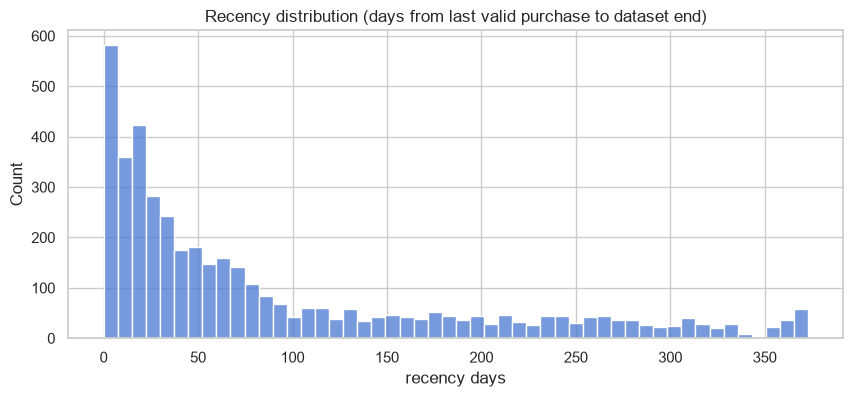

In [16]:
data_end = df["InvoiceDate"].max()
customer_last = valid.groupby("CustomerID")["InvoiceDate"].max()
recency_days = (data_end - customer_last).dt.days
print(recency_days.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).round(2))
plt.figure(figsize=(10, 4))
sns.histplot(recency_days, bins=50)
plt.title("Recency distribution (days from last valid purchase to dataset end)")
plt.xlabel("recency days")
plt.show()


میانه فاصله آخرین خرید معتبر تا پایان داده ۵۰ روز و میانگین آن ۹۱٫۵۴ روز است.
صدک ۷۵ برابر ۱۴۱ روز، صدک ۹۰ برابر ۲۶۲ روز و صدک ۹۵ برابر ۳۱۱ روز است.
این پراکندگی نشان می‌دهد بخشی از مشتریان در ماه‌های آخر فعال بوده‌اند و بخشی مدت‌هاست خرید نکرده‌اند. برای گروه دوم باید در همان زمان مرجع و با توجه به چرخهٔ خرید، خفتگی را بررسی کنم؛ از فاصله تا پایان فایل نمی‌توانم وضعیت او را در هر نقطهٔ برش قبلی نتیجه بگیرم.
برای تعریف پنجره مشاهده و عملکرد، باید همین توزیع را با تقویم کسب‌وکار تطبیق دهم تا چرن با فصل‌بودن اشتباه گرفته نشود. دو تحلیل تکمیلی بعدی همین کار را می‌کنند.

## تحلیل تکمیلی ۱: الگوی ماهانه و فصلی بودن

این تحلیل پاسخ مستقیم یکی از پرسش‌های شماره‌دار نیست، ولی برای تعریف پنجره‌های مشاهده و عملکرد لازم است. تعداد مشتریان فعال، فاکتورها و درآمد معتبر را در هر ماه می‌شمارم.

اینجا خرید ماهانه را می‌بینم و حواسم به ناقص‌بودن ماه آخر هست.
:))

             active_customers  invoices    revenue
InvoiceDate                                       
2010-12                   885      1400   572714.0
2011-01                   741       987   569445.0
2011-02                   758       997   447137.0
2011-03                   974      1321   595501.0
2011-04                   856      1149   469200.0
2011-05                  1056      1555   678595.0
2011-06                   991      1393   661214.0
2011-07                   949      1331   600091.0
2011-08                   935      1280   645344.0
2011-09                  1266      1755   952838.0
2011-10                  1364      1929  1039319.0
2011-11                  1664      2657  1161817.0
2011-12                   615       778   518193.0

last invoice date: 2011-12-09 (December 2011 is a partial month)


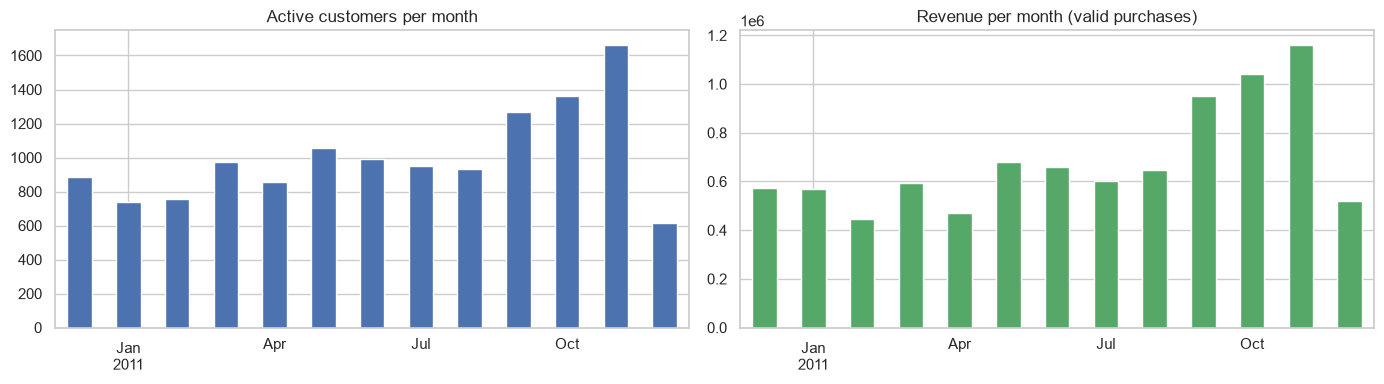

In [17]:
month = valid["InvoiceDate"].dt.to_period("M")
monthly = pd.DataFrame({
    "active_customers": valid.groupby(month)["CustomerID"].nunique(),
    "invoices": valid.groupby(month)["InvoiceNo"].nunique(),
    "revenue": valid.groupby(month)["line_value"].sum().round(0),
})
print(monthly.to_string())
print("\nlast invoice date:", data_end.date(), "(December 2011 is a partial month)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
monthly["active_customers"].plot(kind="bar", ax=axes[0], color="#4c72b0")
axes[0].set_title("Active customers per month")
axes[0].set_xlabel("")
monthly["revenue"].plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("Revenue per month (valid purchases)")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()


تعداد مشتریان فعال در دسامبر ۲۰۱۰ تا آگوست ۲۰۱۱ بین ۷۴۱ و ۱٬۰۵۶ نفر در ماه است و از سپتامبر بالا می‌رود: ۱٬۲۶۶ در سپتامبر، ۱٬۳۶۴ در اکتبر و ۱٬۶۶۴ در نوامبر.
درآمد ماهانه هم از حدود ۴۴۷ تا ۶۷۹ هزار در ماه‌های عادی به ۹۵۳ هزار، ۱٫۰۴ میلیون و ۱٫۱۶ میلیون در سه ماه آخر می‌رسد.
دسامبر ۲۰۱۱ فقط تا روز ۹ ثبت شده و ناقص است.
پس هر پنجره عملکردی که روی سپتامبر تا دسامبر بیفتد، اوج فصل چهارم را در خود دارد.
چون فقط یک سال داده داریم، سال قبلی برای مقایسه هم‌فصل یا تعدیل فصلی نیست و این را باید به‌عنوان محدودیت صریح گزارش کنم.

## تحلیل تکمیلی ۲: مشتری قابل‌امتیازدهی و پنجره‌ها

اینجا با دو نقطهٔ برش و سه شرط تازگی خرید، اندازهٔ جامعهٔ هدف و نرخ توقف خرید را مقایسه می‌کنم. شرط‌های ۹۰، ۱۲۰ و ۱۸۰ روز فرض‌های قابل‌بررسی‌اند، نه تعریف قطعی فعال‌بودن.

افق هر دو مقایسه ۱۰۰ روز تقویمی است. برای اول سپتامبر، بازه به‌صورت `[2011-09-01, 2011-12-10)` تعریف می‌شود تا تمام رکوردهای موجود روز ۹ دسامبر هم حساب شوند. خود روز آخر فایل کامل نیست. این جدول برچسب نهایی مدل نیست.

اینجا اندازهٔ جامعهٔ هدف و توقف خرید را برای چند تعریف آزمایشی مقایسه می‌کنم.


In [18]:
inv_level = valid.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min().reset_index()

def window_table(cutoff, perf_days=100, lookbacks=(90, 120, 180)):
    cutoff = pd.Timestamp(cutoff)
    if cutoff + pd.Timedelta(days=perf_days) > data_end.normalize() + pd.Timedelta(days=1):
        raise ValueError("برای این افق، روزهای کافی در فایل نداریم.")
    obs_inv = inv_level[inv_level["InvoiceDate"] < cutoff]
    perf_inv = inv_level[(inv_level["InvoiceDate"] >= cutoff) & (inv_level["InvoiceDate"] < cutoff + pd.Timedelta(days=perf_days))]
    last_obs = obs_inv.groupby("CustomerID")["InvoiceDate"].max()
    bought = set(perf_inv["CustomerID"])
    rows = []
    for lb in lookbacks:
        eligible = last_obs[last_obs >= cutoff - pd.Timedelta(days=lb)].index
        rows.append({
            "cutoff": cutoff.date(),
            "lookback_days": lb,
            "customers_in_observation": len(last_obs),
            "eligible": len(eligible),
            "dormant": len(last_obs) - len(eligible),
            "hard_churn_percent": round((1 - len(set(eligible) & bought) / len(eligible)) * 100, 1) if len(eligible) else np.nan,
        })
    return pd.DataFrame(rows)

windows = pd.concat([window_table("2011-09-01"), window_table("2011-06-01")], ignore_index=True)
print(windows.to_string(index=False))
print("\nPerformance window: 100 calendar days; [1 Sep, 10 Dec) includes all available records on 9 Dec. Last calendar day is partial.")

    cutoff  lookback_days  customers_in_observation  eligible  dormant  hard_churn_percent
2011-09-01             90                      3317      1923     1394                29.2
2011-09-01            120                      3317      2298     1019                31.9
2011-09-01            180                      3317      2772      545                36.6
2011-06-01             90                      2718      1959      759                40.9
2011-06-01            120                      2718      2247      471                43.8
2011-06-01            180                      2718      2659       59                47.6

Performance window: 100 calendar days; [1 Sep, 10 Dec) includes all available records on 9 Dec. Last calendar day is partial.


این جدول نشان می‌دهد با عوض‌کردن شرط تازگی و زمان مرجع، تعداد مشتری‌های واجد شرایط و نرخ توقف خرید تغییر می‌کند. برای انتخاب ۱۲۰ روز فقط به یک درصد نگاه نمی‌کنم؛ باید چرخهٔ خرید و تعداد مشتری‌های کنارمانده را هم ببینم.

تفاوت دو نقطهٔ برش می‌تواند با فصل، ترکیب مشتری‌ها و طول سابقهٔ مشاهده مرتبط باشد؛ این مقایسه اثر فصل را به‌تنهایی ثابت نمی‌کند. مقدار دقیق نرخ‌ها را از جدول همین اجرا می‌خوانم، چون مرز بازه اصلاح شده است. نبود خرید در این افق هم لزوماً رفتن همیشگی مشتری نیست.

# بخش چهارم

# تحلیل ویژگی‌های عددی

## سوال ۱۶

آمار توصیفی کامل ویژگی‌های عددی را استخراج کنید.

اینجا مرکز، پراکندگی و انتهای توزیع عددها را روی دادهٔ خام می‌بینم.


In [19]:
line_value = df["Quantity"] * df["UnitPrice"]
numeric_view = pd.DataFrame({
    "Quantity": df["Quantity"],
    "UnitPrice": df["UnitPrice"],
    "LineValue": line_value,
})
numeric_view.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T.round(2)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.55,218.08,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.61,96.76,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0
LineValue,541909.0,17.99,378.81,-168469.60,-6.58,0.83,3.40,9.75,17.40,59.40,180.0,168469.6


`Quantity` میانه ۳ و میانگین ۹٫۵۵ دارد، اما انحراف معیار آن ۲۱۸٫۰۸ است.
`UnitPrice` میانه ۲٫۰۸ و میانگین ۴٫۶۱ دارد و انحراف معیار آن ۹۶٫۷۶ است.
`LineValue` که فقط برای تحلیل ساخته‌ام میانه ۹٫۷۵ و میانگین ۱۷٫۹۹ دارد.
این آمار نشان می‌دهد هر سه متغیر تحت تأثیر مقادیر بسیار بزرگ‌اند و نمی‌توان فقط به میانگین تکیه کرد.

## سوال ۱۷

برای هر ویژگی عددی میانگین، میانه و مد را محاسبه کنید.

اینجا میانگین، میانه و پرتکرارترین مقدار را مقایسه می‌کنم.


In [20]:
summary = pd.DataFrame({
    "mean": numeric_view.mean(),
    "median": numeric_view.median(),
    "mode": [numeric_view[c].mode().iloc[0] for c in numeric_view.columns],
})
summary.round(2)

,mean,median,mode
Quantity,9.55,3.00,1.00
UnitPrice,4.61,2.08,1.25
LineValue,17.99,9.75,15.00


مد `Quantity` برابر ۱ است، یعنی فراوان‌ترین مقدار یک واحد کالا است.
مد `UnitPrice` برابر ۱٫۲۵ است و میانه ۲٫۰۸، که نشان‌دهنده تمرکز قیمت‌ها در بازه پایین است.
فاصله میانگین و میانه در `Quantity` و `UnitPrice` از چولگی راست و وجود سفارش‌های بزرگ حکایت می‌کند.
به همین دلیل در مدل‌سازی بعدی، تبدیل لگاریتمی و مقیاس‌بندی مقاوم را جدی می‌گیرم.

## سوال ۱۸

برای هر ویژگی عددی واریانس و انحراف معیار را محاسبه کنید.

اینجا پراکندگی و اختلاف مقیاس‌ها را می‌سنجم.


In [21]:
pd.DataFrame({
    "variance": numeric_view.var(),
    "std": numeric_view.std(),
}).round(2)

,variance,std
Quantity,47559.39,218.08
UnitPrice,9362.47,96.76
LineValue,143497.64,378.81


واریانس `Quantity` حدود ۴۷٬۵۵۹ و انحراف معیار آن ۲۱۸٫۰۸ است.
واریانس `UnitPrice` حدود ۹٬۳۶۲ و انحراف معیار آن ۹۶٫۷۶ است.
واریانس `LineValue` هم بسیار بزرگ‌تر از میانگین آن است.
این اختلاف مقیاس یعنی K-Means بدون استانداردسازی تحت سلطه `Quantity` و `LineValue` قرار می‌گیرد و باید پیش‌پردازش مقیاس انجام شود.

## سوال ۱۹

برای تمام ویژگی‌های عددی Histogram رسم کنید.

اینجا فقط نسخهٔ نمایشی را clip می‌کنم تا نمودار خواناتر شود؛ روی مرزها تجمع مصنوعی ممکن است ایجاد شود.


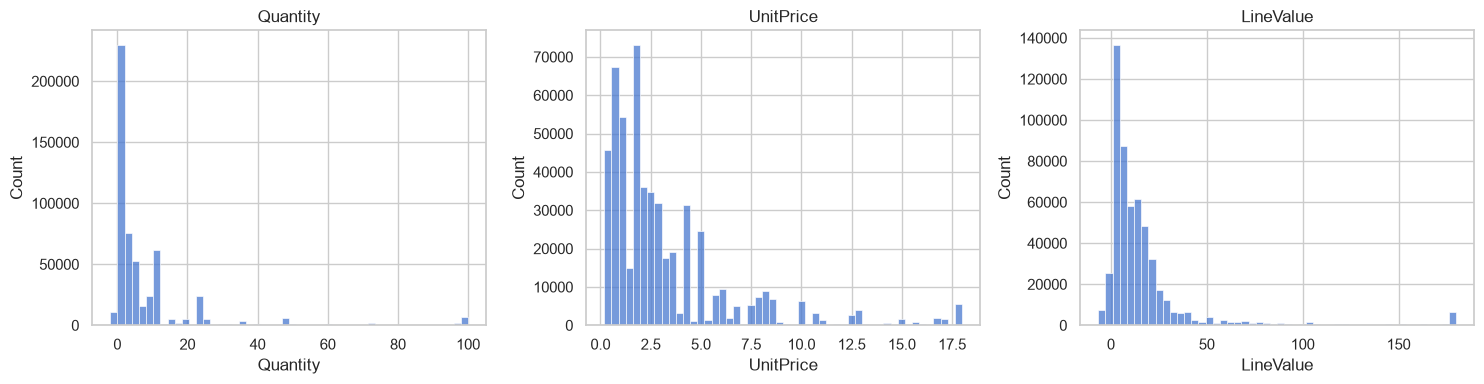

In [22]:
plot_view = numeric_view.copy()
for col in plot_view.columns:
    lo, hi = plot_view[col].quantile([.01, .99])
    plot_view[col] = plot_view[col].clip(lo, hi)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, plot_view.columns):
    sns.histplot(plot_view[col], bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

هیستوگرام‌ها نشان می‌دهند `Quantity` و `UnitPrice` در بازه‌های کوچک متمرکزند و دنباله بلندی به سمت مقادیر بزرگ دارند.
`LineValue` نیز بسیار راست‌چوله است و بخش زیادی از ردیف‌ها ارزش کوچک دارند.
برای خوانایی، در نسخهٔ نمایشی مقادیر بیرون صدک‌های ۱ و ۹۹ را با clip روی مرزها قرار داده‌ام؛ این کار می‌تواند روی مرزها تجمع مصنوعی بسازد. دادهٔ خام تغییر نکرده و این نمودار توزیع کامل خام نیست.
این شکل توزیع، استفاده از مدل‌های مقاوم به ناهنجاری و تبدیل لگاریتمی را توجیه می‌کند.

## سوال ۲۰

برای تمام ویژگی‌های عددی Boxplot رسم کنید.

اینجا باکس‌پلات همان نسخهٔ نمایشی را می‌کشم؛ اندازهٔ واقعی انتهاها را از آمار خام می‌خوانم.


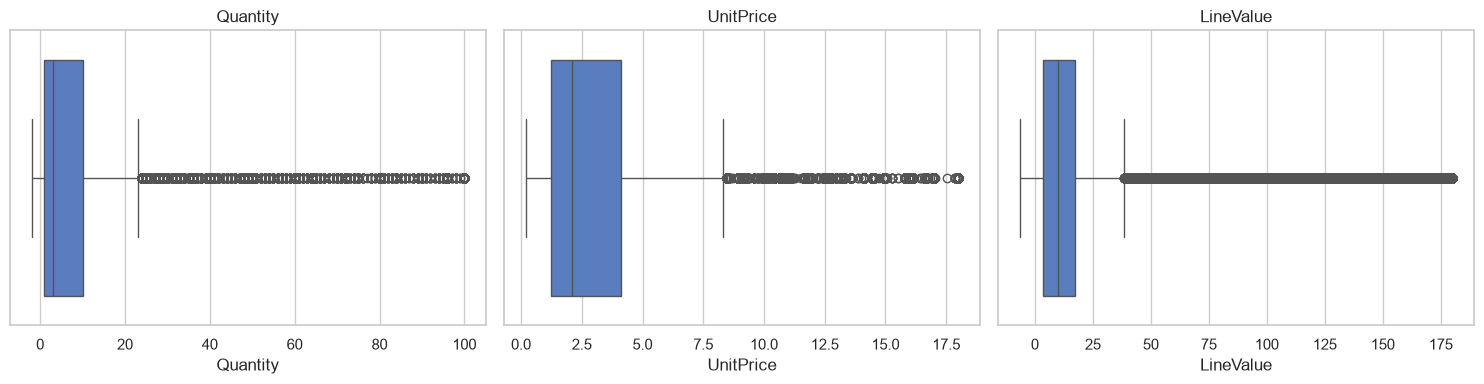

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, plot_view.columns):
    sns.boxplot(x=plot_view[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

باکس‌پلات‌ها نشان می‌دهند میانه `Quantity` و `UnitPrice` بسیار پایین است، اما دامنه مقادیر پرت بسیار وسیع است.
در `LineValue` نیز جعبه اصلی بسیار فشرده و دنباله پرت بسیار بلند است.
برای خوانایی، دامنه نمایش را با برش صدک ۱ و ۹۹ محدود کرده‌ام و داده اصلی تغییر نکرده است.
این الگو نیاز به بررسی مقادیر افراطی را نشان می‌دهد؛ به‌تنهایی ثابت نمی‌کند اجرای Isolation Forest قبل از هر مدل ضروری است. نمودار روی نسخهٔ clipشده است و برای دیدن اندازهٔ واقعی انتهاها باید آمار خام را هم بخوانم.

## سوال ۲۱

برای تمام ویژگی‌های عددی KDE Plot رسم کنید.

اینجا نمای هموارشدهٔ همان توزیع نمایشی را می‌بینم.


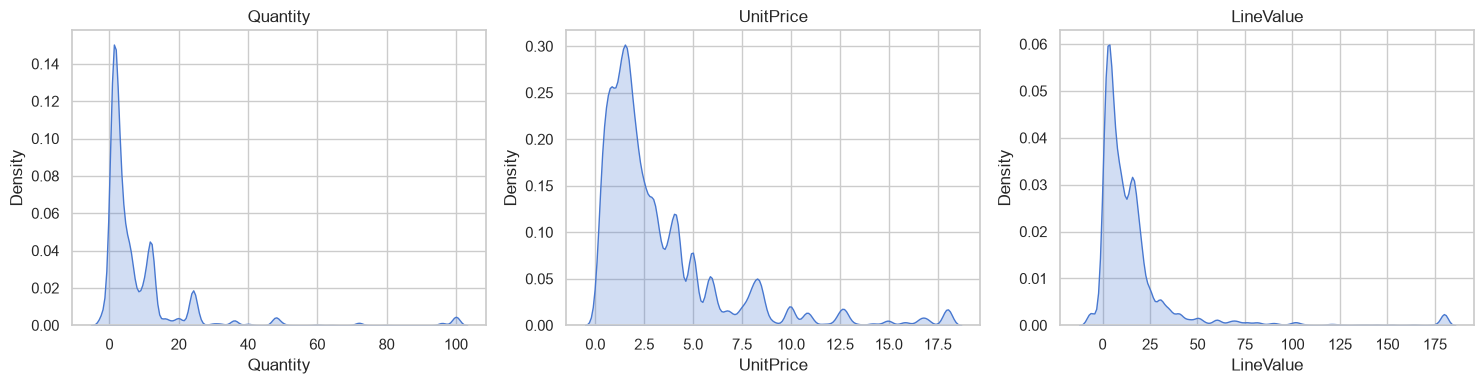

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, plot_view.columns):
    sns.kdeplot(plot_view[col], fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

نمودار چگالی `Quantity` یک قله تیز نزدیک یک دارد و برای مقادیر بزرگ تقریباً صفر می‌شود.
`UnitPrice` نیز چگالی بسیار متمرکزی در قیمت‌های پایین دارد و دنباله آن در نمایش دیده نمی‌شود.
`LineValue` تک‌قله‌ای و به‌شدت راست‌چوله است.
این نمودار روی دادهٔ نمایشیِ clipشده رسم شده و برای شناخت تمرکز مقادیر است. از روی KDE آستانهٔ Isolation Forest تعیین نمی‌کنم؛ برای Quantity گسسته هم هیستوگرام تفسیر مستقیم‌تری دارد.

# بخش پنجم

# تحلیل ویژگی‌های دسته‌ای

## سوال ۲۲

فراوانی تمام ویژگی‌های دسته‌ای را محاسبه کنید.

اینجا تعداد سطح‌ها و پرتکرارترین مقدارهای دسته‌ای را می‌خوانم.


In [25]:
for col in ["Country", "StockCode", "Description"]:
    print(f"--- {col} ---")
    print("unique levels:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(10).to_string())

--- Country ---
unique levels: 38


Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
--- StockCode ---
unique levels: 4070


StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
84879     1502
22720     1477
22197     1476
21212     1385
20727     1350
--- Description ---
unique levels: 4224
Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
NaN                                   1454
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350


`Country` فقط ۳۸ سطح دارد و `StockCode` و `Description` هزاران سطح دارند.
پرتکرارترین کشور بریتانیا با ۴۹۵٬۴۷۸ ردیف است و پس از آن آلمان، فرانسه، ایرلند و اسپانیا قرار دارند.
در سطح کالا، `85123A` با ۲٬۳۱۳ ردیف و `22423` با ۲٬۲۰۳ ردیف پرتکرارترین‌اند.
تعداد زیاد سطوح کالا برای Apriori چالش‌برانگیز است، ولی برای قواعد انجمنی می‌توان روی محصولات پرتکرار تمرکز کرد.
بخشی از این کدها کالا نیستند (مثل `POST` و `DOT` و `AMAZONFEE`)؛ تحلیل تکمیلی ۳ آن‌ها را جدا می‌کند.

## سوال ۲۳

برای ویژگی‌های دسته‌ای Countplot رسم کنید.

اینجا ده کشور پرتکرار را در سطح ردیف نمایش می‌دهم؛ این سهم مشتری نیست.


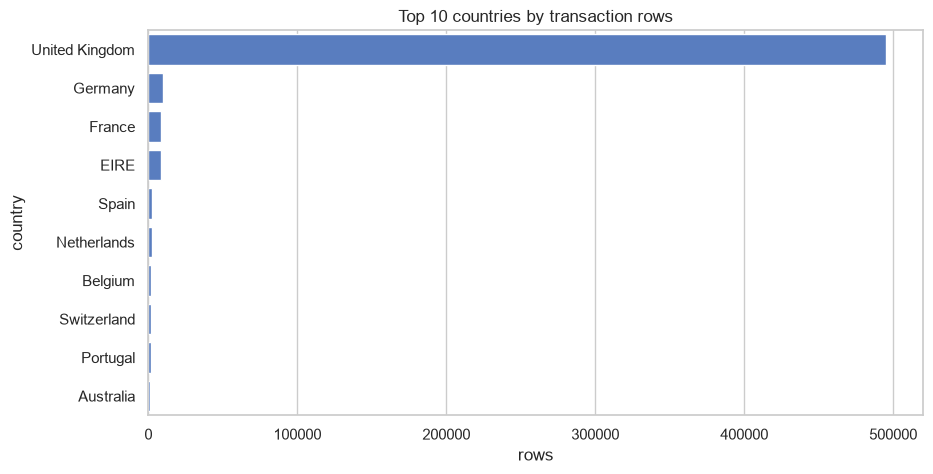

In [26]:
top_countries = df["Country"].value_counts().head(10).index
plt.figure(figsize=(10, 5))
sns.countplot(data=df[df["Country"].isin(top_countries)], y="Country", order=top_countries)
plt.title("Top 10 countries by transaction rows")
plt.xlabel("rows")
plt.ylabel("country")
plt.show()

نمودار فراوانی کشورها نشان می‌دهد بریتانیا تقریباً کل داده را در اختیار دارد و بازارهای دیگر بسیار کوچک‌ترند.
این عدم تعادل جغرافیایی باعث می‌شود مدل‌هایی که `Country` را به‌عنوان ویژگی دارند، بیش‌ازحد به بریتانیا وابسته شوند.
کشورهای کوچک برای تحلیل نرخ تکرار ارزش دارند، اما نمونه‌شان برای نتیجه‌گیری قطعی کافی نیست.
ادغام کشورها یا حذف این ویژگی گزینه‌هایی برای بررسی‌اند، نه الزام. تصمیم را با توزیع سطح مشتری و فایدهٔ مدل می‌گیرم؛ نامتوازن‌بودن کشور به‌تنهایی وزن‌دهی را توجیه نمی‌کند.

## سوال ۲۴

توزیع کشور را با درصد بررسی کنید.

اینجا سهم کشورها از ردیف‌ها را حساب می‌کنم.


In [27]:
country_counts = df["Country"].value_counts()
print(country_counts.head(10).to_string())
print("UK share percent:", round(country_counts["United Kingdom"] / len(df) * 100, 2))
print("non-UK share percent:", round((len(df) - country_counts["United Kingdom"]) / len(df) * 100, 2))

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
UK share percent: 91.43
non-UK share percent: 8.57


سهم بریتانیا از ردیف‌ها حدود ۹۱٫۴۳ درصد است و سهم همه کشورهای دیگر کمتر از ۹ درصد می‌شود.
آلمان با ۹٬۴۹۵ ردیف، فرانسه با ۸٬۵۵۷ ردیف و ایرلند با ۸٬۱۹۶ ردیف بزرگ‌ترین بازارهای غیربریتانیایی‌اند.
این توزیع نشان می‌دهد تحلیل چرن در سطح کل داده عمدتاً رفتار مشتریان بریتانیایی را می‌سنجد.
برای تحلیل بازارهای دیگر باید نمونه‌های کوچک را با احتیاط تفسیر کرد.

## سوال ۲۵

توزیع وضعیت فاکتورها و سهم برگشت، لغو و قیمت صفر را بررسی کنید.

اینجا وضعیت‌های لغو و مقدارهای خاص را دوباره کنار هم می‌بینم؛ درصدها قابل‌جمع نیستند.


In [28]:
status_flags = pd.DataFrame({
    "cancellation_invoice": df["InvoiceNo"].astype(str).str.startswith("C"),
    "negative_quantity": df["Quantity"] < 0,
    "zero_unit_price": df["UnitPrice"] == 0,
    "negative_line_value": line_value < 0,
    "zero_line_value": line_value == 0,
})
status_summary = pd.DataFrame({
    "count": status_flags.sum(),
    "percent": (status_flags.mean() * 100).round(2),
})
status_summary

,count,percent
cancellation_invoice,9288,1.71
negative_quantity,10624,1.96
zero_unit_price,2515,0.46
negative_line_value,9290,1.71
zero_line_value,2515,0.46


حدود ۱٫۷۱ درصد ردیف‌ها (متعلق به ۳٬۸۳۶ فاکتور یکتا) با حرف C شروع می‌شوند و ۱٫۹۶ درصد ردیف‌ها تعداد منفی دارند.
۰٫۴۶ درصد ردیف‌ها قیمت واحد صفر دارند و ۱٫۷۱ درصد ارزش خط منفی است.
این اعداد نشان می‌دهند داده فقط فروش خالص نیست و برگشت، لغو و اصلاح را هم در خود دارد.
برای تحلیل سبد و ارزش عمر، باید این وضعیت‌ها را در Data Preparation به‌صورت شفاف مدل کرد، نه اینکه بی‌صدا حذف شوند.

## تحلیل تکمیلی ۳: ردیف‌های غیرمحصولی

برخی `StockCode`ها کالا نیستند، بلکه هزینه ارسال، کارمزد، تخفیف یا اصلاح حساب‌اند. این‌ها روی درآمد، تعداد محصول متمایز و قواعد انجمنی اثر می‌گذارند، پس جداگانه می‌شمارمشان.

اینجا فهرست اولیهٔ کدهای غیرمحصولی را جدا بررسی می‌کنم؛ فهرست هنوز نیاز به بازبینی دارد.


In [29]:
NON_PRODUCT_CODES = ["POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES", "AMAZONFEE", "CRUK", "PADS"]

np_rows = df[df["StockCode"].astype(str).isin(NON_PRODUCT_CODES)].copy()
np_rows["value"] = np_rows["Quantity"] * np_rows["UnitPrice"]
print("non-product rows:", len(np_rows), "| percent of all rows:", round(len(np_rows) / len(df) * 100, 2))
np_table = np_rows.groupby("StockCode").agg(
    rows=("value", "size"),
    net_value=("value", "sum"),
    description=("Description", lambda s: str(s.dropna().iloc[0]) if s.notna().any() else ""),
).sort_values("rows", ascending=False).round(0)
print(np_table.to_string())
print("\nnet value of these rows:", round(np_rows["value"].sum()), "| net value of all rows:", round(line_value.sum()))


non-product rows: 2915 | percent of all rows: 0.54
              rows  net_value                 description
StockCode                                                
POST          1256    66231.0                     POSTAGE
DOT            710   206245.0              DOTCOM POSTAGE
M              571   -68674.0                      Manual
C2             144     6986.0                    CARRIAGE
D               77    -5696.0                    Discount
S               63    -3049.0                     SAMPLES
BANK CHARGES    37    -7176.0                Bank Charges
AMAZONFEE       34  -221520.0                  AMAZON FEE
CRUK            16    -7933.0             CRUK Commission
PADS             4        0.0  PADS TO MATCH ALL CUSHIONS
B                3   -11062.0             Adjust bad debt

net value of these rows: -45649 | net value of all rows: 9747748


یازده کد غیرمحصولی، شامل `POST`، `DOT`، `M` (Manual)، `C2` (Carriage)، `D` (Discount)، `S` (Samples)، `BANK CHARGES`، `AMAZONFEE`، `CRUK` (کمیسیون)، `PADS` و `B` (Adjust bad debt)، روی هم ۲٬۹۱۵ ردیف هستند، یعنی ۰٫۵۴ درصد ردیف‌ها.
اثر مالی‌شان بزرگ‌تر از سهم ردیفی‌شان است: `DOT` حدود ۲۰۶ هزار به درآمد خالص اضافه می‌کند و `AMAZONFEE` حدود ۲۲۲ هزار از آن کم می‌کند. جمع خالص این ردیف‌ها حدود ۴۶ هزار منفی است.
وجود `AMAZONFEE` نشان می‌دهد بخشی از فروش از راه آمازون هم ثبت می‌شود، ولی فقط به‌صورت ردیف کارمزد و نه داده کانال فروش.
این کدها را در شمارش تنوع محصول و تحلیل سبد کنار گذاشته‌ام. در Data Preparation هم باید به‌جای حذف بی‌صدا، صریحاً علامت بخورند. فهرست `NON_PRODUCT_CODES` پیشنهاد اولیه من است و باید بازبینی شود.

# بخش ششم

# ارتباط ویژگی‌ها با رفتار چرن و مشتری

## سوال ۲۶

توزیع Quantity و UnitPrice را بین خریداران یک‌باره و چندباره مقایسه کنید.

اینجا رفتار ردیف‌های مشتری تک‌خریدی و تکراری را مقایسه می‌کنم؛ مشتری‌های پُرردیف وزن بیشتری دارند.


In [30]:
cust_invoice_count = valid.groupby("CustomerID")["InvoiceNo"].nunique()
valid_ct = valid.assign(customer_type=np.where(valid["CustomerID"].map(cust_invoice_count) >= 2, "repeat", "one-time"))
comparison = valid_ct.groupby("customer_type")[["Quantity", "UnitPrice", "line_value"]].agg(["mean", "median"]).round(2)
print(comparison)
revenue_share = valid_ct.groupby("customer_type")["line_value"].sum()
print("\nrevenue share percent (valid purchases, before returns):")
print((revenue_share / revenue_share.sum() * 100).round(2))


              Quantity        UnitPrice        line_value       
                  mean median      mean median       mean median
customer_type                                                   
one-time         12.08    4.0      3.12   1.95      18.39   10.5
repeat           13.07    6.0      3.12   1.95      22.77   11.9

revenue share percent (valid purchases, before returns):
customer_type
one-time     6.92
repeat      93.08
Name: line_value, dtype: float64


میانگین `Quantity` در خریداران یک‌باره ۱۲٫۰۸ و در خریداران تکراری ۱۳٫۰۷ است.
میانه `Quantity` برای این دو گروه به‌ترتیب ۴ و ۶ است.
میانگین و میانه `UnitPrice` در دو گروه یکسان است (۳٫۱۲ و ۱٫۹۵)، و میانه ارزش هر ردیف از ۱۰٫۵۰ به ۱۱٫۹۰ می‌رسد.
تفاوت‌ها زیاد نیستند، بنابراین تعداد فاکتور و ارزش کل مشتری باید محور اصلی تحلیل چرن باشد، نه فقط اندازه یک قلم.
مشتریان تکراری حدود ۹۳٫۰۸ درصد ارزش خرید معتبر را می‌سازند، در حالی که سهم یک‌باره‌ها فقط ۶٫۹۲ درصد است. این سهم‌ها پیش از کسر برگشت‌ها هستند.

## سوال ۲۷

آیا مشتریانی که فاکتور بیشتری دارند ارزش کل خرید بالاتری هم دارند؟

اینجا رابطهٔ تعداد فاکتور و مبلغ کل را در سطح مشتری می‌سنجم.


Pearson:
          invoices  value  quantity
invoices     1.000  0.554     0.558
value        0.554  1.000     0.923
quantity     0.558  0.923     1.000

Spearman:
          invoices  value  quantity
invoices     1.000  0.807     0.761
value        0.807  1.000     0.928
quantity     0.761  0.928     1.000


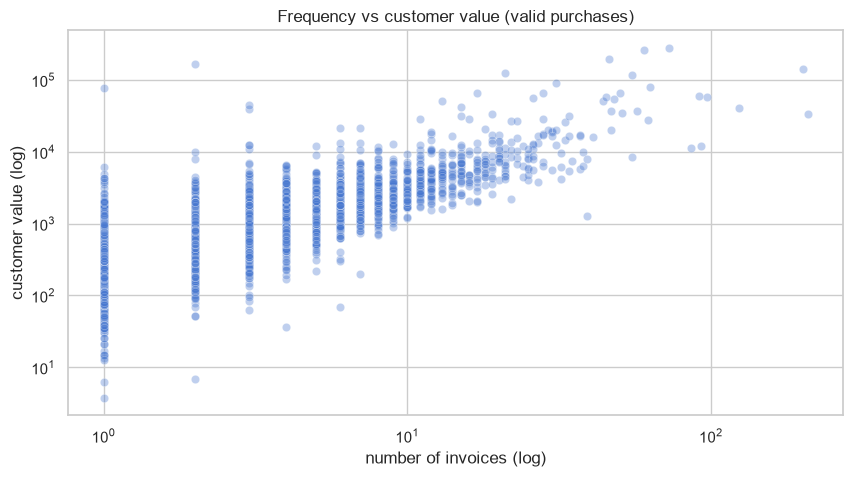

In [31]:
cust_value = valid.groupby("CustomerID").agg(
    invoices=("InvoiceNo", "nunique"),
    value=("line_value", "sum"),
    quantity=("Quantity", "sum"),
)
print("Pearson:")
print(cust_value.corr().round(3))
print("\nSpearman:")
print(cust_value.corr(method="spearman").round(3))
sns.scatterplot(data=cust_value, x="invoices", y="value", alpha=0.35)
plt.xscale("log")
plt.yscale("log")
plt.title("Frequency vs customer value (valid purchases)")
plt.xlabel("number of invoices (log)")
plt.ylabel("customer value (log)")
plt.show()


همبستگی پیرسون تعداد فاکتور و ارزش کل خرید مشتری ۰٫۵۵۴ و همبستگی اسپیرمن ۰٫۸۰۷ است.
این اختلاف نشان می‌دهد رابطه در رتبه‌ها قوی است، ولی چند مشتری با ارزش بسیار بالا پیرسون را پایین می‌کشند.
نمودار لگاریتمی نیز نشان می‌دهد چند مشتری با تعداد فاکتور کم ارزش بسیار بالایی دارند.
بنابراین برای خوشه‌بندی، `Frequency` و `Monetary` را با هم می‌گیرم و فقط به یکی بسنده نمی‌کنم.

## سوال ۲۸

رابطه تعداد اقلام هر فاکتور با ارزش همان فاکتور را بررسی کنید.

اینجا حجم و مبلغ سبد را در سطح فاکتور کنار هم می‌گذارم.


Pearson:
       items  value
items  1.000  0.907
value  0.907  1.000

Spearman:
       items  value
items  1.000  0.838
value  0.838  1.000


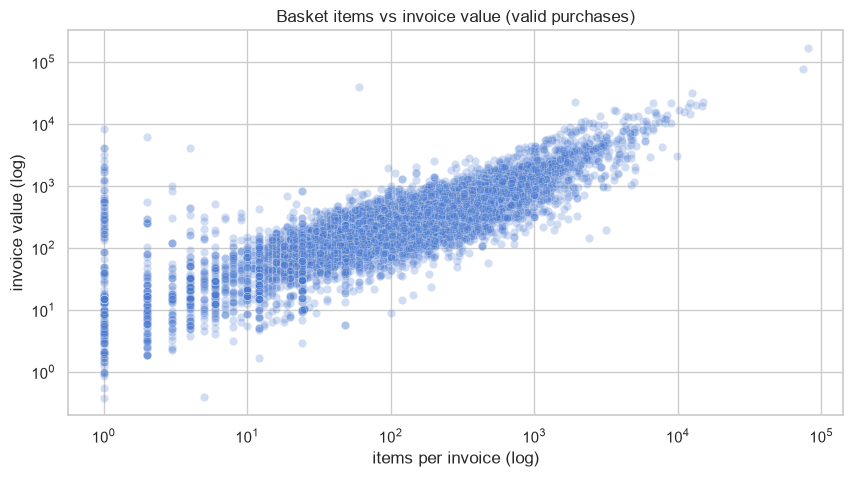

In [32]:
invoice_view = valid.groupby("InvoiceNo").agg(
    items=("Quantity", "sum"),
    value=("line_value", "sum"),
)
print("Pearson:")
print(invoice_view.corr().round(3))
print("\nSpearman:")
print(invoice_view.corr(method="spearman").round(3))
sns.scatterplot(data=invoice_view, x="items", y="value", alpha=0.25)
plt.xscale("log")
plt.yscale("log")
plt.title("Basket items vs invoice value (valid purchases)")
plt.xlabel("items per invoice (log)")
plt.ylabel("invoice value (log)")
plt.show()


همبستگی تعداد اقلام هر فاکتور با ارزش آن قوی و مثبت است (پیرسون ۰٫۹۰۷ و اسپیرمن ۰٫۸۳۸).
فاکتورهای با اقلام زیاد همیشه ارزش بالا ندارند، چون قیمت واحد کالاها متفاوت است. همین باعث می‌شود همبستگی رتبه‌ای کمتر از پیرسون باشد، چون چند فاکتور بسیار بزرگ پیرسون را بالا می‌برند.
چند فاکتور با ارزش بسیار بالا نیز در نمودار لگاریتمی از بقیه جدا می‌افتند.
این موضوع نشان می‌دهد ارزش فاکتور باید هم‌زمان با تعداد اقلام و قیمت واحد تحلیل شود.

## سوال ۲۹

نرخ تکرار خرید در کشورهای اصلی را مقایسه کنید.

اینجا نرخ تکرار را به تفکیک کشور توصیف می‌کنم؛ فعلاً کشور هر شناسه را از اولین مقدار می‌گیرم.


In [33]:
country_customer = valid.groupby("CustomerID").agg(
    country=("Country", "first"),
    invoices=("InvoiceNo", "nunique"),
)
country_repeat = country_customer.groupby("country").agg(
    customers=("invoices", "size"),
    repeat_rate=("invoices", lambda s: (s >= 2).mean() * 100),
    avg_invoices=("invoices", "mean"),
).sort_values("customers", ascending=False).head(12)
country_repeat.round(2)


,customers,repeat_rate,avg_invoices
country,,,
United Kingdom,3920,65.56,4.25
Germany,94,72.34,4.86
France,87,67.82,4.47
Spain,28,64.29,3.04
Belgium,24,75.00,4.08
Switzerland,20,75.00,2.60
Portugal,19,63.16,3.00
Italy,14,42.86,2.71
Finland,12,58.33,3.42


نرخ تکرار خرید در بریتانیا ۶۵٫۵۶ درصد و در آلمان ۷۲٫۳۴ درصد است.
فرانسه ۶۷٫۸۲ درصد، پرتغال ۶۳٫۱۶ درصد و سوئیس ۷۵ درصد نرخ تکرار دارند.
ایتالیا با ۴۲٫۸۶ درصد (۱۴ مشتری) و اتریش با ۴۴٫۴۴ درصد (۹ مشتری) کمترین نرخ‌ها را دارند، ولی نمونه‌شان بسیار کوچک است.
بریتانیا ۳٬۹۲۰ مشتری از ۴٬۳۳۸ مشتری را دارد، یعنی حدود ۹۰ درصد.
این تفاوت‌ها می‌تواند به ترکیب مشتریان، هزینه ارسال یا اندازه بازار مربوط باشد و باید با احتیاط و توجه به تعداد مشتریان تفسیر شود.

## سوال ۳۰

برای کشورهای اصلی جدول توافقی یک‌باره و چندباره بسازید.

اینجا ترکیب مشتری‌های تک‌خریدی و تکراری هر کشور را درصدی می‌بینم.


In [34]:
top_countries = country_customer["country"].value_counts().head(10).index
subset = country_customer[country_customer["country"].isin(top_countries)].copy()
subset["repeat"] = subset["invoices"] >= 2
ct = pd.crosstab(subset["country"], subset["repeat"], normalize="index") * 100
ct.columns = ["one-time_percent", "repeat_percent"]
ct.round(2)


,one-time_percent,repeat_percent
country,,
Belgium,25.00,75.00
Finland,41.67,58.33
France,32.18,67.82
Germany,27.66,72.34
Italy,57.14,42.86
Norway,40.00,60.00
Portugal,36.84,63.16
Spain,35.71,64.29
Switzerland,25.00,75.00


جدول توافقی نشان می‌دهد در بیشتر کشورهای اصلی، سهم مشتریان تکراری از یک‌باره‌ها بیشتر است. استثنا ایتالیاست که ۵۷٫۱۴ درصد یک‌باره دارد.
در بریتانیا ۳۴٫۴۴ درصد یک‌باره و ۶۵٫۵۶ درصد تکراری‌اند، که تقریباً همان الگوی کل داده است.
آلمان و سوئیس سهم تکراری بالاتری دارند، ولی نمونه آلمان ۹۴ و نمونه سوئیس ۲۰ مشتری است.
بنابراین الگوی کشورها را توصیفی می‌دانم. فلگ بریتانیا/غیربریتانیا یک گزینهٔ ساده برای مقایسه است، ولی کافی‌بودنش باید بررسی شود. در کد، کشور هر مشتری با اولین مقدار موجود انتخاب شده؛ قبل از استفادهٔ مدل باید چندکشوری‌بودن احتمالی شناسه‌ها هم بررسی شود.

## سوال ۳۱

آیا مشتریان با تنوع محصول بیشتر، خرید تکراری بیشتری دارند؟

اینجا تنوع محصول را مقایسه می‌کنم؛ خرید بیشتر خودش فرصت تنوع بیشتری می‌دهد.


         count   mean    std  min   25%   50%    75%     max
repeat                                                      
False   1493.0  21.59  21.35  0.0   8.0  16.0   28.0   219.0
True    2845.0  82.24  97.91  1.0  28.0  56.0  104.0  1785.0


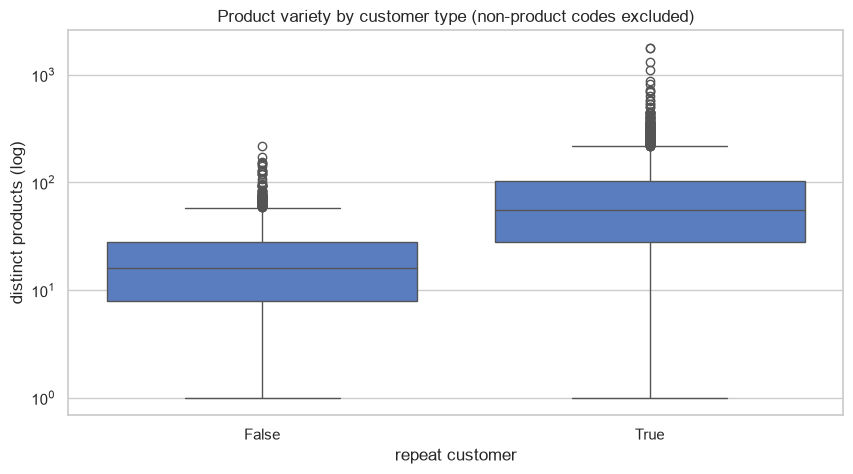

In [35]:
products_only = valid[~valid["StockCode"].astype(str).isin(NON_PRODUCT_CODES)]
cust_products = pd.DataFrame({
    "products": products_only.groupby("CustomerID")["StockCode"].nunique(),
    "invoices": customer_invoices,
}).fillna(0)
cust_products["products"] = cust_products["products"].astype(int)
cust_products["repeat"] = cust_products["invoices"] >= 2
print(cust_products.groupby("repeat")["products"].describe().round(2))
plot_data = cust_products[cust_products["products"] > 0]
sns.boxplot(data=plot_data, x="repeat", y="products")
plt.yscale("log")
plt.title("Product variety by customer type (non-product codes excluded)")
plt.xlabel("repeat customer")
plt.ylabel("distinct products (log)")
plt.show()


میانه تعداد محصولات متمایز خریداری‌شده در مشتریان یک‌باره ۱۶ و در مشتریان تکراری ۵۶ است.
میانگین این متغیر از ۲۱٫۵۹ به ۸۲٫۲۴ افزایش می‌یابد و دنباله پرت مشتریان تکراری طولانی‌تر است (بیشینه ۱٬۷۸۵).
در این شمارش، کدهای غیرمحصولی کنار گذاشته شده‌اند.
این رابطه برای توصیف رفتار مفید است، ولی مشتری تکراری فرصت بیشتری برای دیدن و خریدن کالاهای متنوع داشته است؛ بنابراین هنوز شاهد پیش‌بینی وفاداری یا ریزش نیست.
البته جهت علیت را نمی‌توان از این داده استنباط کرد و فقط هم‌روندی را می‌بینم.

## تحلیل تکمیلی ۴: تمرکز درآمد و مشتریان عمده

طبق پلن، مشتریان عمده را حذف نمی‌کنم و جدا تحلیل می‌کنم. برای این کار باید بدانم درآمد چقدر روی چند مشتری متمرکز است.

اینجا تمرکز مبلغ خرید مثبت را می‌سنجم؛ این مبلغ هنوز بعد از کسر و تطبیق مرجوعی‌ها نیست.


top 1% of customers (43) hold 31.8% of valid-purchase revenue
top 5% of customers (216) hold 50.3% of valid-purchase revenue
top 10% of customers (433) hold 61.3% of valid-purchase revenue
top 20% of customers (867) hold 74.6% of valid-purchase revenue
top 10 customers hold: 17.3 % of revenue

customers with a single line of Quantity >= 1000: 45
customers with a single line of Quantity >= 500: 95
overlap between top-1% value and Quantity>=500 customers: 28


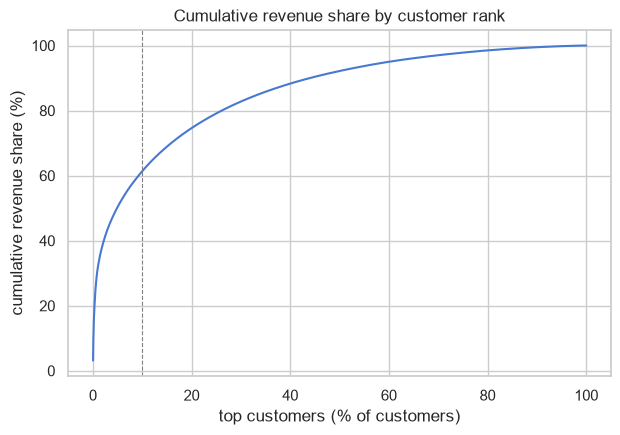

In [36]:
cust_gross = valid.groupby("CustomerID")["line_value"].sum().sort_values(ascending=False)
total = cust_gross.sum()
for pct in (0.01, 0.05, 0.10, 0.20):
    k = int(len(cust_gross) * pct)
    print(f"top {pct:.0%} of customers ({k}) hold {cust_gross.head(k).sum() / total * 100:.1f}% of valid-purchase revenue")
print("top 10 customers hold:", round(cust_gross.head(10).sum() / total * 100, 1), "% of revenue")

max_line_qty = valid.groupby("CustomerID")["Quantity"].max()
print("\ncustomers with a single line of Quantity >= 1000:", int((max_line_qty >= 1000).sum()))
print("customers with a single line of Quantity >= 500:", int((max_line_qty >= 500).sum()))
top1 = set(cust_gross.head(int(len(cust_gross) * 0.01)).index)
big_qty = set(max_line_qty[max_line_qty >= 500].index)
print("overlap between top-1% value and Quantity>=500 customers:", len(top1 & big_qty))

x = np.arange(1, len(cust_gross) + 1) / len(cust_gross)
y = cust_gross.cumsum() / total
plt.figure(figsize=(7, 4.5))
plt.plot(x * 100, y.values * 100)
plt.axvline(10, color="grey", linestyle="--", linewidth=0.8)
plt.title("Cumulative revenue share by customer rank")
plt.xlabel("top customers (% of customers)")
plt.ylabel("cumulative revenue share (%)")
plt.show()


یک درصد بالای مشتریان (۴۳ نفر) ۳۱٫۸ درصد درآمد معتبر را می‌سازند. ۵ درصد بالا ۵۰٫۳ درصد، ۱۰ درصد بالا ۶۱٫۳ درصد و ۲۰ درصد بالا ۷۴٫۶ درصد را در اختیار دارند. فقط ۱۰ مشتری اول ۱۷٫۳ درصد درآمد را دارند.
۴۵ مشتری دست‌کم یک ردیف با `Quantity` بالای ۱۰۰۰ و ۹۵ مشتری بالای ۵۰۰ دارند، که الگوی عمده‌فروشی است. از ۹۵ مشتری با ردیف بزرگ، ۲۸ نفر هم‌زمان در یک درصد بالای ارزش‌اند، پس این دو معیار هم‌پوشانی دارند ولی یکی نیستند.
این تمرکز یعنی حذف خودکار پرت‌ها دقیقاً ارزشمندترین مشتریان را از بین می‌برد.
در Data Preparation یک پرچم «عمده/حجیم» می‌سازم و تحلیل را در دو لایه انجام می‌دهم. چرخه خرید طولانی‌تر این گروه هم یعنی پنجره عملکرد ۹۹ روزه برای بعضی از آن‌ها کوتاه است.

# بخش هفتم

# تحلیل روابط بین ویژگی‌ها

## سوال ۳۲

ماتریس همبستگی ویژگی‌های عددی را در سطح ردیف و سطح مشتری محاسبه کنید.

اینجا همبستگی ردیف و مشتری را جدا می‌سازم تا دو سطح تحلیل قاطی نشوند.


In [37]:
row_corr = pd.DataFrame({
    "Quantity": df["Quantity"],
    "UnitPrice": df["UnitPrice"],
    "LineValue": line_value,
}).corr()

customer_table = cust_value.join(cust_products["products"])
customer_corr = customer_table.corr()
customer_corr_sp = customer_table.corr(method="spearman")

print("Row-level correlation (Pearson):")
print(row_corr.round(3))
print("\nCustomer-level correlation (Pearson):")
print(customer_corr.round(3))
print("\nCustomer-level correlation (Spearman):")
print(customer_corr_sp.round(3))


Row-level correlation (Pearson):
           Quantity  UnitPrice  LineValue
Quantity      1.000     -0.001      0.887
UnitPrice    -0.001      1.000     -0.162
LineValue     0.887     -0.162      1.000

Customer-level correlation (Pearson):
          invoices  value  quantity  products
invoices     1.000  0.554     0.558     0.692
value        0.554  1.000     0.923     0.387
quantity     0.558  0.923     1.000     0.410
products     0.692  0.387     0.410     1.000

Customer-level correlation (Spearman):
          invoices  value  quantity  products
invoices     1.000  0.807     0.761     0.656
value        0.807  1.000     0.928     0.726
quantity     0.761  0.928     1.000     0.727
products     0.656  0.726     0.727     1.000


در سطح ردیف، `Quantity` و `LineValue` همبستگی ۰٫۸۸۷ دارند و `UnitPrice` با `LineValue` همبستگی منفی ۰٫۱۶۲ دارد.
در سطح مشتری، پیرسون `invoices` با `products` ۰٫۶۹۲ و با `value` ۰٫۵۵۴ است و `quantity` با `value` ۰٫۹۲۳ همبستگی دارد.
همبستگی اسپیرمن در همین سطح، رابطه `invoices` و `value` را ۰٫۸۰۷ نشان می‌دهد. این تفاوت از مشتریان عمده می‌آید.
در خوشه‌بندی باید مراقب باشم چند ویژگی مشابه به یک بُعد رفتار وزن اضافی ندهند. درخت تصمیم الزام حذف ویژگی هم‌بسته ندارد، ولی تفسیر اهمیت ویژگی‌ها ممکن است دشوارتر شود.

## سوال ۳۳

Heatmap همبستگی را رسم کنید.

اینجا همان رابطه‌ها را تصویری می‌بینم.


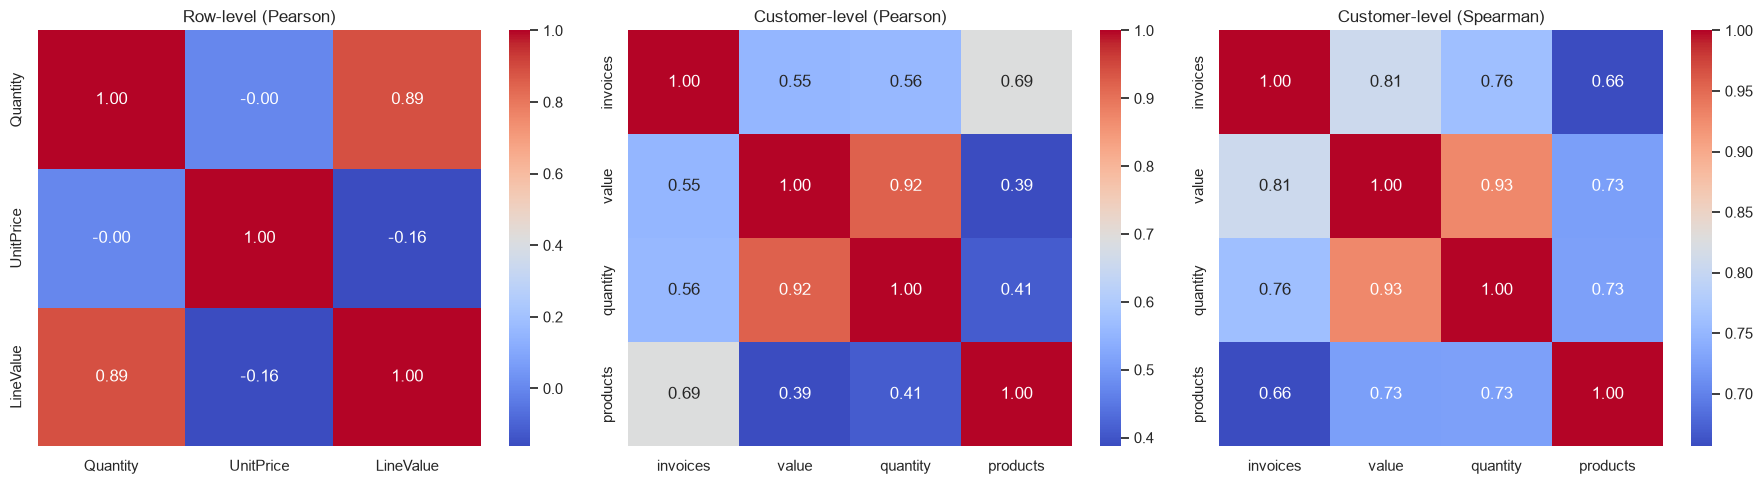

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.heatmap(row_corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0])
axes[0].set_title("Row-level (Pearson)")
sns.heatmap(customer_corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Customer-level (Pearson)")
sns.heatmap(customer_corr_sp, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[2])
axes[2].set_title("Customer-level (Spearman)")
plt.tight_layout()
plt.show()


Heatmap نشان می‌دهد بلوک `Quantity` و `LineValue` در سطح ردیف بسیار داغ است و بقیه رابطه‌ها ضعیف‌ترند.
در سطح مشتری، `quantity` و `value` یک بلوک مثبت قوی می‌سازند.
در نسخه اسپیرمن، رابطه `invoices` و `products` با `value` قوی‌تر دیده می‌شود (۰٫۸۰۷ و ۰٫۷۲۶). یعنی در رتبه‌بندی مشتریان این متغیرها هم‌جهت‌اند، ولی پیرسون به‌خاطر چند مشتری عمده آن‌ها را کمتر نشان می‌دهد.
این نقشه برای انتخاب ویژگی‌های خوشه‌بندی و کاهش هم‌خطی راهنمای خوبی است.

## سوال ۳۴

بیشترین همبستگی مثبت و منفی با ارزش مشتری مربوط به کدام ویژگی‌هاست؟

اینجا رابطهٔ ویژگی‌های موجود با مبلغ کل را مرتب می‌کنم؛ این رابطه با ریزش نیست.


In [39]:
corr_with_value = customer_corr["value"].drop("value").sort_values()
corr_sp = customer_corr_sp["value"].drop("value").sort_values()
print("Pearson:")
print(corr_with_value.round(3))
print("most positive:", corr_with_value.idxmax(), round(corr_with_value.max(), 3))
print("\nSpearman:")
print(corr_sp.round(3))
print("most positive:", corr_sp.idxmax(), round(corr_sp.max(), 3))
if corr_with_value.min() < 0:
    print("most negative:", corr_with_value.idxmin(), round(corr_with_value.min(), 3))
else:
    print("most negative: none (all correlations are positive)")


Pearson:
products    0.387
invoices    0.554
quantity    0.923
Name: value, dtype: float64
most positive: quantity 0.923

Spearman:
products    0.726
invoices    0.807
quantity    0.928
Name: value, dtype: float64
most positive: quantity 0.928
most negative: none (all correlations are positive)


در سطح مشتری، `quantity` با پیرسون ۰٫۹۲۳ (اسپیرمن ۰٫۹۲۸) قوی‌ترین رابطه مثبت را با `value` دارد.
پس از آن `invoices` با ۰٫۵۵۴ (اسپیرمن ۰٫۸۰۷) و `products` با ۰٫۳۸۷ (اسپیرمن ۰٫۷۲۶) قرار دارند.
هیچ ویژگی عددی در این مجموعه همبستگی منفی با `value` ندارد.
تفاوت پیرسون و اسپیرمن در `invoices` و `products` نشان می‌دهد این رابطه‌ها به مشتریان عمده حساس‌اند.
این نتیجه نشان می‌دهد ارزش مشتری بیشتر با حجم خرید و تعداد فاکتور توضیح داده می‌شود تا با قیمت واحد؛ در سطح ردیف هم `UnitPrice` رابطه‌ای ضعیف و منفی (۰٫۱۶۲−) با ارزش دارد.

## سوال ۳۵

سه جفت ویژگی با بالاترین همبستگی را پیدا کنید.

اینجا قوی‌ترین همبستگی‌ها را پیدا می‌کنم تا مراقب ویژگی‌های تکراری باشم.


In [40]:
pairs = []
for i in range(len(customer_corr.columns)):
    for j in range(i + 1, len(customer_corr.columns)):
        pairs.append((
            customer_corr.index[i],
            customer_corr.columns[j],
            customer_corr.iloc[i, j],
            customer_corr_sp.iloc[i, j],
        ))
pair_df = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson", "spearman"])
pair_df["abs_pearson"] = pair_df["pearson"].abs()
pair_df.sort_values("abs_pearson", ascending=False).head(3).round(3)


,feature_1,feature_2,pearson,spearman,abs_pearson
3,value,quantity,0.923,0.928,0.923
2,invoices,products,0.692,0.656,0.692
1,invoices,quantity,0.558,0.761,0.558


سه جفت با بالاترین همبستگی پیرسون در سطح مشتری عبارت‌اند از `quantity` و `value` (۰٫۹۲۳)، `invoices` و `products` (۰٫۶۹۲)، و `quantity` و `invoices` (۰٫۵۵۸).
جفت اول برای تفسیر ضرایب برخی مدل‌های رگرسیونی نیاز به توجه دارد؛ برای CART به‌خودی‌خود ایراد جدی یا الزام حذف نیست.
جفت دوم نشان می‌دهد مشتریان با فاکتور بیشتر، تنوع محصول بیشتری هم می‌خرند و جفت سوم حجم خرید را به تعداد فاکتور گره می‌زند. در رتبه (اسپیرمن) جفت سوم قوی‌تر است (۰٫۷۶۱).
حذف یا ترکیب ویژگی‌ها فقط یکی از گزینه‌هاست و باید با نوع مدل و نتیجهٔ ارزیابی توجیه شود؛ PCA هم انتخاب اجباری نیست.

## سوال ۳۶

Scatter Plot و Pairplot برای ویژگی‌های مهم رسم کنید.

اینجا یک نمونهٔ ثابت برای دیدن شکل رابطه‌ها رسم می‌کنم.


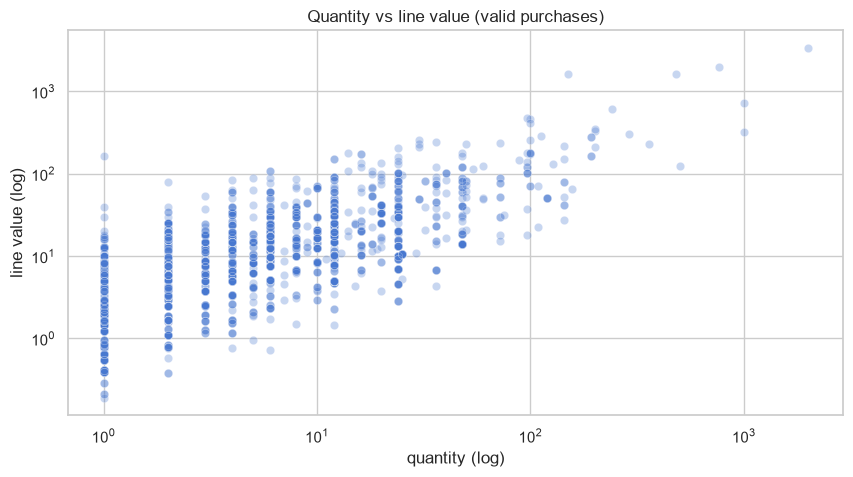

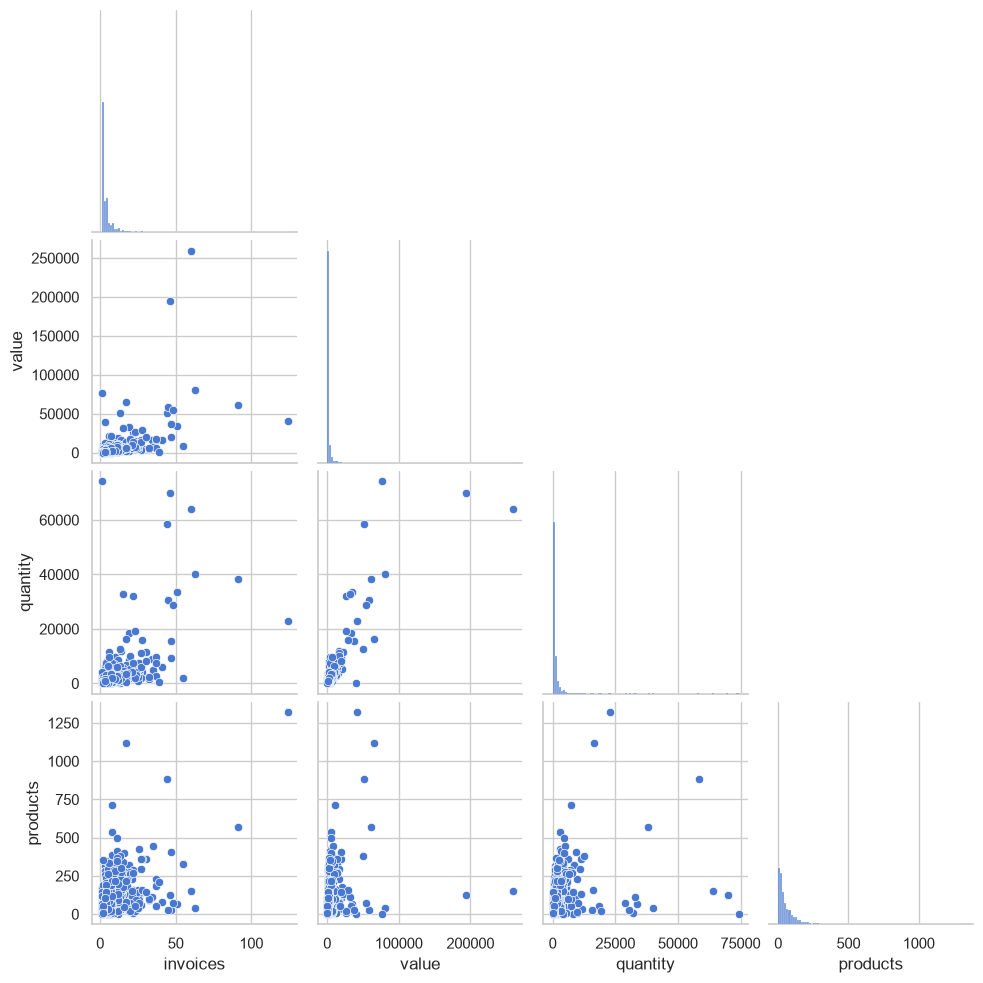

In [41]:
sample_rows = valid.sample(3000, random_state=42)
sns.scatterplot(data=sample_rows, x="Quantity", y="line_value", alpha=0.3)
plt.xscale("log")
plt.yscale("log")
plt.title("Quantity vs line value (valid purchases)")
plt.xlabel("quantity (log)")
plt.ylabel("line value (log)")
plt.show()

pair_data = customer_table.sample(2000, random_state=42)
sns.pairplot(pair_data, corner=True)
plt.show()


نمودار پراکندگی `Quantity` و `LineValue` رابطه مثبت ولی با پراکندگی زیاد نشان می‌دهد.
نقاط با مقدار بسیار بزرگ در گوشه بالا سمت راست دیده می‌شوند و بر مقیاس غلبه می‌کنند، به همین دلیل از محور لگاریتمی استفاده کرده‌ام.
Pairplot سطح مشتری نیز جدایی نسبی مشتریان کم‌فعالیت و پرفعالیت را نشان می‌دهد.
این الگوها برای K-Means امیدوارکننده‌اند، ولی بدون استانداردسازی و مدیریت ناهنجاری قابل اعتماد نیستند.

# بخش هشتم

# تحلیل چندمتغیره و آمادگی پنج مرحله مدل‌سازی

## سوال ۳۷

سه پروفایل تحلیلی مشتری کم‌ارزش، میان‌ارزش و پرارزش بسازید.

اینجا مشتری‌ها را موقتاً بر اساس مبلغ به سه بخش تقسیم می‌کنم؛ این خوشه‌بندی یا درجهٔ خطر نیست.


In [42]:
profile = customer_table.copy()
profile["value_segment"] = pd.qcut(profile["value"], 3, labels=["low", "mid", "high"], duplicates="drop")
profile_summary = profile.groupby("value_segment", observed=True).agg(
    customers=("invoices", "size"),
    avg_invoices=("invoices", "mean"),
    median_invoices=("invoices", "median"),
    avg_value=("value", "mean"),
    median_value=("value", "median"),
    avg_products=("products", "mean"),
    repeat_rate=("invoices", lambda s: (s >= 2).mean() * 100),
).round(2)
profile_summary


,customers,avg_invoices,median_invoices,avg_value,median_value,avg_products,repeat_rate
value_segment,,,,,,,
low,1446,1.33,1.0,220.60,215.80,18.58,24.83
mid,1446,2.57,2.0,712.59,674.48,46.13,75.45
high,1446,8.92,6.0,5229.61,2437.85,119.40,96.47


با تقسیم مشتریان به سه گروه ارزشی، گروه کم‌ارزش ۱٬۴۴۶ مشتری با میانگین ۱٫۳۳ فاکتور و ارزش میانگین ۲۲۰٫۶۰ دارد.
گروه میان‌ارزش ۱٬۴۴۶ مشتری با میانگین ۲٫۵۷ فاکتور و ارزش ۷۱۲٫۵۹ دارد.
گروه پرارزش ۱٬۴۴۶ مشتری با میانگین ۸٫۹۲ فاکتور (میانه ۶)، ارزش میانگین ۵٬۲۲۹٫۶۱ در برابر میانه ۲٬۴۳۷٫۸۵ و نرخ تکرار ۹۶٫۴۷ درصد دارد. شکاف میانگین و میانه در این گروه دنباله مشتریان عمده را نشان می‌دهد.
این سه پروفایل نشان می‌دهد بخش بزرگی از ارزش از گروه پرارزش و وفادار می‌آید و استراتژی نگه‌داشت باید متناسب با گروه باشد.

## سوال ۳۸

داده برای Isolation Forest چه ناهنجاری‌هایی دارد؟

اینجا چند آستانهٔ ساده و IQR را برای شناخت مقادیر متفاوت بررسی می‌کنم؛ این‌ها برچسب خطا نیستند.


In [43]:
outlier_summary = pd.DataFrame({
    "count": [
        int((df["Quantity"] < 0).sum()),
        int((df["UnitPrice"] <= 0).sum()),
        int((line_value < 0).sum()),
        int((df["Quantity"] > 1000).sum()),
        int((df["UnitPrice"] > 100).sum()),
        int((line_value > 10000).sum()),
    ],
    "percent": [
        round((df["Quantity"] < 0).mean() * 100, 2),
        round((df["UnitPrice"] <= 0).mean() * 100, 2),
        round((line_value < 0).mean() * 100, 2),
        round((df["Quantity"] > 1000).mean() * 100, 2),
        round((df["UnitPrice"] > 100).mean() * 100, 2),
        round((line_value > 10000).mean() * 100, 2),
    ],
}, index=["Quantity < 0", "UnitPrice <= 0", "LineValue < 0", "Quantity > 1000", "UnitPrice > 100", "LineValue > 10000"])
print(outlier_summary)

iqr_rows = []
for name, s in [("Quantity", df["Quantity"]), ("UnitPrice", df["UnitPrice"]), ("LineValue", line_value)]:
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lo) | (s > hi)
    iqr_rows.append((name, int(mask.sum()), round(mask.mean() * 100, 2)))
print("\nIQR outliers:")
print(pd.DataFrame(iqr_rows, columns=["feature", "iqr_outliers", "iqr_percent"]).to_string(index=False))

                   count  percent
Quantity < 0       10624     1.96
UnitPrice <= 0      2517     0.46
LineValue < 0       9290     1.71
Quantity > 1000      116     0.02
UnitPrice > 100     1036     0.19
LineValue > 10000      5     0.00



IQR outliers:
  feature  iqr_outliers  iqr_percent
 Quantity         58619        10.82
UnitPrice         39627         7.31
LineValue         44997         8.30


حدود ۱۰٫۸۲ درصد `Quantity`، ۷٫۳۱ درصد `UnitPrice` و ۸٫۳۰ درصد `LineValue` بیرون از محدوده IQR قرار می‌گیرند.
۱۱۶ ردیف `Quantity` بالای ۱۰۰۰، ۱٬۰۳۶ ردیف `UnitPrice` بالای ۱۰۰ و ۵ ردیف `LineValue` بالای ۱۰٬۰۰۰ دارند.
همچنین تعداد منفی، قیمت صفر و فاکتورهای لغو شده وجود دارد.
این‌ها دو دسته‌اند. تعداد منفی، قیمت صفر، لغو و اصلاح بدهی خطا یا ورودی غیرفروش‌اند و با قاعده در Data Preparation مدیریت می‌شوند، نه با Isolation Forest.
مقادیر معتبر ولی افراطی، مثل خریدهای عمده، کار Isolation Forest هستند و باید آن را روی جدول مشتری اجرا کنم، نه روی ردیف‌های خام. پارامتر کلیدی آن نسبت آلودگی (`contamination`) است که با تحلیل حساسیت تعیین می‌شود، چون برچسب ناهنجاری برای ارزیابی در داده نیست.

## تحلیل تکمیلی ۵: کاندیداهای ناهنجاری در سطح مشتری

اینجا با چند قاعدهٔ ساده مشتری‌های متفاوت را علامت می‌زنم تا ببینم حذف عجولانهٔ پرت‌ها چه کسانی را تحت‌تأثیر می‌گذارد. نه این قواعد و نه Isolation Forest داور قطعی خطا نیستند؛ نتیجه نیاز به بررسی دارد.

اینجا جدول مشتری و پرچم‌های اولیه می‌سازم. نسبت مرجوعی، مبلغ اسناد C به خرید مثبت در همین بازه است؛ نه سهم مرجوعیِ تطبیق‌داده‌شده با سفارش.


In [44]:
# جدول موقت RFM سطح مشتری؛ فقط برای شناسایی کاندیداهای ناهنجاری، بدون حذف چیزی.
returns = df[df["CustomerID"].notna() & df["InvoiceNo"].astype(str).str.startswith("C")]
return_value = (-(returns["Quantity"] * returns["UnitPrice"])).groupby(returns["CustomerID"]).sum()

rfm = valid.groupby("CustomerID").agg(
    frequency=("InvoiceNo", "nunique"),
    monetary=("line_value", "sum"),
    last_purchase=("InvoiceDate", "max"),
    max_line_qty=("Quantity", "max"),
)
rfm["recency"] = (data_end - rfm["last_purchase"]).dt.days
rfm["return_ratio"] = (return_value.reindex(rfm.index).fillna(0) / rfm["monetary"]).round(3)

cand = pd.DataFrame({
    "monetary_above_p99": rfm["monetary"] > rfm["monetary"].quantile(.99),
    "frequency_above_p99": rfm["frequency"] > rfm["frequency"].quantile(.99),
    "single_line_qty_ge_1000": rfm["max_line_qty"] >= 1000,
    "return_ratio_above_30pct": rfm["return_ratio"] > 0.30,
})
print("customers in RFM table:", len(rfm))
print(cand.sum().to_string())
flagged = cand.any(axis=1)
print("\ncustomers flagged by at least one rule:", int(flagged.sum()), f"({flagged.mean() * 100:.1f}%)")
print("share of valid-purchase revenue held by flagged customers:", round(rfm.loc[flagged, "monetary"].sum() / rfm["monetary"].sum() * 100, 1), "%")
print("\nreturn ratio distribution (customers with any return):")
print(rfm.loc[rfm["return_ratio"] > 0, "return_ratio"].describe(percentiles=[.5, .9, .99]).round(3))


customers in RFM table: 4338
monetary_above_p99          44
frequency_above_p99         42
single_line_qty_ge_1000     45
return_ratio_above_30pct    79

customers flagged by at least one rule: 161 (3.7%)
share of valid-purchase revenue held by flagged customers: 36.7 %

return ratio distribution (customers with any return):
count    1549.000
mean        0.111
std         1.462
min         0.001
50%         0.022
90%         0.151
99%         1.000
max        57.051
Name: return_ratio, dtype: float64


۴۴ مشتری ارزش خرید بالای صدک ۹۹، ۴۲ مشتری فرکانس بالای صدک ۹۹ و ۴۵ مشتری دست‌کم یک ردیف با `Quantity` بالای ۱۰۰۰ دارند. ۷۹ مشتری هم نسبت برگشت بالای ۳۰ درصد دارند.
در مجموع ۱۶۱ مشتری (۳٫۷ درصد) دست‌کم یک قاعده را فعال می‌کنند و همین گروه ۳۶٫۷ درصد درآمد معتبر را در دست دارند. یعنی کاندیداهای ناهنجاری با مشتریان ارزشمند هم‌پوشانی زیادی دارند و حذف‌شان ریسک مالی دارد.
نسبت برگشت خودش ویژگی بالقوه ریزش است. از ۱٬۵۴۹ مشتری با دست‌کم یک برگشت، میانه نسبت ۲٫۲ درصد و صدک ۹۹ برابر ۱۰۰ درصد است و بیشینه به ۵۷ برابر می‌رسد. این نسبت برای مشتریان با خرید کم ناپایدار است و باید با احتیاط ساخته شود.

## سوال ۳۹

داده برای K-Means چه پیش‌نیازهایی دارد؟

اینجا چولگی خام و مشتری‌محور را جدا می‌بینم و اثر log1p را فقط آزمایش می‌کنم.


In [45]:
valid_rows = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
valid_rows_value = valid_rows["Quantity"] * valid_rows["UnitPrice"]

skew_table = pd.DataFrame({
    "skew_all_rows": [df["Quantity"].skew(), df["UnitPrice"].skew(), line_value.skew()],
    "skew_valid_rows": [valid_rows["Quantity"].skew(), valid_rows["UnitPrice"].skew(), valid_rows_value.skew()],
    "kurtosis_valid_rows": [valid_rows["Quantity"].kurtosis(), valid_rows["UnitPrice"].kurtosis(), valid_rows_value.kurtosis()],
}, index=["Quantity", "UnitPrice", "LineValue"])
print(skew_table.round(2))
print("\nlargest order and its cancellation:")
print(df.loc[df["Quantity"].abs() == 80995, ["InvoiceNo", "Quantity", "UnitPrice", "CustomerID"]].to_string())

rfm_view = rfm[["recency", "frequency", "monetary"]]
rfm_skew = pd.DataFrame({
    "skew_raw": rfm_view.skew(),
    "skew_after_log1p": np.log1p(rfm_view).skew(),
    "std_raw": rfm_view.std(),
}).round(2)
print("\ncustomer-level RFM (the table K-Means will actually use):")
print(rfm_skew)
print("\ncategorical columns:", df.select_dtypes(include=["object", "string"]).columns.tolist())
print("UK share of rows (%):", round((df["Country"] == "United Kingdom").mean() * 100, 2))
print("missing CustomerID percent:", round(df["CustomerID"].isna().mean() * 100, 2))


           skew_all_rows  skew_valid_rows  kurtosis_valid_rows
Quantity           -0.26           471.73            236462.34
UnitPrice         186.51           206.09             62483.14
LineValue          -0.96           506.71            297651.66

largest order and its cancellation:
       InvoiceNo  Quantity  UnitPrice  CustomerID
540421    581483     80995       2.08     16446.0
540422   C581484    -80995       2.08     16446.0

customer-level RFM (the table K-Means will actually use):
           skew_raw  skew_after_log1p  std_raw
recency        1.25             -0.55   100.01
frequency     12.07              1.21     7.70
monetary      19.32              0.39  8989.23

categorical columns: ['InvoiceNo', 'StockCode', 'Description', 'Country']
UK share of rows (%): 91.43
missing CustomerID percent: 24.93


روی همه ردیف‌ها، چولگی `Quantity` برابر ۰٫۲۶− و `LineValue` برابر ۰٫۹۶− است که گمراه‌کننده است: سفارش ۸۰٬۹۹۵ تایی و لغو دقیق آن (فاکتور `C581484`) یکدیگر را خنثی می‌کنند.
روی ردیف‌های معتبر، چولگی `Quantity` حدود ۴۷۱٫۷ و `LineValue` حدود ۵۰۶٫۷ و `UnitPrice` حدود ۲۰۶٫۱ است و کشیدگی هر سه بسیار زیاد است. پس هر سه ویژگی ردیف‌محور به‌شدت راست‌چوله‌اند.
جدولی که K-Means واقعاً می‌گیرد سطح مشتری است. چولگی `recency` ۱٫۲۵، `frequency` ۱۲٫۰۷ و `monetary` ۱۹٫۳۲ است و پس از `log1p` به ۰٫۵۵−، ۱٫۲۱ و ۰٫۳۹ می‌رسد. تبدیل لگاریتمی چولگی را به‌طور محسوس کم می‌کند، ولی `frequency` هنوز راست‌چوله می‌ماند. انحراف معیار خام `monetary` (۸٬۹۸۹) و `recency` (۱۰۰) هم بسیار متفاوت است، پس استانداردسازی لازم است.
ستون `Country` دسته‌ای است، ولی ۹۱٫۴۳ درصد ردیف‌ها بریتانیایی‌اند و اطلاعات کمی می‌دهد. فلگ بریتانیا/غیربریتانیا یا حذف کشور را می‌توانم مقایسه کنم؛ از سهم ردیف‌ها به‌تنهایی نمی‌شود بهترین نمایش کشور یا نیاز به روش دیگری را تعیین کرد.
بنابراین قبل از خوشه‌بندی به تبدیل لگاریتمی و استانداردسازی روی جدول مشتری نیاز دارم.

## سوال ۴۰

داده برای CART چه محدودیت‌ها و پیش‌نیازهایی دارد؟

اینجا محدودیت‌های ساخت مدل ریزش را جمع‌بندی می‌کنم.


In [46]:
print("target exists:", "target" in df.columns)
print("date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("days covered:", (df["InvoiceDate"].max() - df["InvoiceDate"].min()).days)
print("customers with at least one valid purchase:", len(customer_invoices))
print("one-time percent (valid purchases):", round((customer_invoices == 1).mean() * 100, 2))
print("missing CustomerID percent:", round(df["CustomerID"].isna().mean() * 100, 2))


target exists: False
date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
days covered: 373
customers with at least one valid purchase: 4338
one-time percent (valid purchases): 34.42
missing CustomerID percent: 24.93


اینجا می‌بینم برچسب آمادهٔ ریزش ندارم و باید آن را با تعریف روشن و بازه‌های زمانی بسازم. نبود شناسه و کمبود سابقهٔ مشتری، محدودیت پوشش و ساخت ویژگی‌اند؛ خودشان نشت اطلاعات نیستند. نشت زمانی رخ می‌دهد که اطلاعات بعد از زمان مرجع وارد ورودی مدل شود.

نرخ‌های جدول آزمایشی فقط مربوط به توقف خرید و تعریف همان جدول‌اند، نه برچسب نهاییِ ترکیبی سخت و نرم. دربارهٔ عدم‌توازن نهایی بعد از ساخت آن برچسب تصمیم می‌گیرم. ویژگی، خوشه و تبدیل‌ها هم باید در هر ارزیابی فقط از دادهٔ مجاز آموزش ساخته شوند.

## سوال ۴۱

داده برای Apriori/FP-Growth و BG/NBD/Gamma-Gamma چه وضعیتی دارد؟

اینجا ساختار سبد و میزان سابقهٔ تکرار را برای امکان‌سنجی روش‌های مکمل بررسی می‌کنم.


In [47]:
basket = valid[~valid["StockCode"].astype(str).isin(NON_PRODUCT_CODES)]
items_per_invoice = basket.groupby("InvoiceNo")["StockCode"].nunique()
inv_value = valid.groupby("InvoiceNo")["line_value"].sum()
print("unique product codes (non-product codes excluded):", basket["StockCode"].nunique())
print("valid invoices with at least one product:", len(items_per_invoice))
print("invoices with >= 2 distinct products:", int((items_per_invoice >= 2).sum()))
print("multi-product invoice percent:", round((items_per_invoice >= 2).mean() * 100, 2))
print("median distinct products per invoice:", float(items_per_invoice.median()))
print("median invoice value (valid purchases):", round(float(inv_value.median()), 2))
print("repeat customer percent (valid purchases):", round((customer_invoices >= 2).mean() * 100, 2))
print("median gap days:", float(gaps.median()))
print("observation days:", (df["InvoiceDate"].max() - df["InvoiceDate"].min()).days)


unique product codes (non-product codes excluded): 3659
valid invoices with at least one product: 18402
invoices with >= 2 distinct products: 17087
multi-product invoice percent: 92.85
median distinct products per invoice: 15.0
median invoice value (valid purchases): 303.04
repeat customer percent (valid purchases): 65.58
median gap days: 21.0
observation days: 373


بخش بزرگی از فاکتورهای این زیرمجموعه چند محصول متمایز دارند؛ پس ساختار سبد برای بررسی قواعد خرید مناسب به نظر می‌رسد. مقدار دقیق تعداد کالا، سبد و مبلغ را از خروجی بالا می‌خوانم. میانهٔ مبلغ در کد روی همهٔ فاکتورهای جدول مقدماتی valid است، نه الزاماً همان سبدهای بدون کد غیرمحصولی.

برای BG/NBD، تاریخ خریدها و مشتری‌های تکراری در دسترس‌اند، ولی تعریف رویداد خرید مهم است: چند فاکتور نزدیک به هم ممکن است لازم باشد طبق واحد زمانی مدل به یک رویداد تبدیل شوند. تک‌خریدی‌ها می‌توانند با صفر خرید تکراری در BG/NBD باشند.

Gamma-Gamma معمولاً میانگین مبلغ خریدهای تکراری مثبت را می‌گیرد، نه مبلغ کل مشتری. چولگی مبلغ کل به‌تنهایی ضرورت تبدیل ورودی آن را نشان نمی‌دهد؛ ورود log1p به جای مبلغ هم بدون توجیه، مدل استاندارد را تغییر می‌دهد. سابقهٔ کافی و رابطهٔ مبلغ متوسط با تکرار خرید باید روی پنجرهٔ آموزش بررسی شوند. برای افراد بدون خرید تکراری، برآورد فردیِ مبتنی بر آن سابقه ندارم و باید روش گروهی یا جایگزین شفاف تعریف کنم.

# گزارش نهایی

## ۱

مهم‌ترین ویژگی‌های مرتبط با چرن کدام‌اند؟

مهم‌ترین محورها تعداد فاکتور، فاصله آخرین خرید، روند خرید، تنوع محصول، ارزش کل و اندازه سبد هستند. این‌ها فرضیه‌اند، چون هنوز برچسب چرن ندارم و مقایسه یک‌باره و تکراری فقط تقریبی از آن است. مشتریان تکراری ۹۳٫۰۸ درصد ارزش خرید معتبر را می‌سازند و گروه پرارزش نرخ تکرار حدود ۹۶ درصد دارد. تفاوت `Quantity` و `UnitPrice` بین یک‌باره و تکراری کم است، پس از این مقایسه به‌تنهایی نمی‌توان دربارهٔ قدرت پیش‌بینی چرن آن‌ها نتیجه گرفت. بنابراین ویژگی‌های رفتاری و زمانی باید در مرکز مدل CART قرار بگیرند و ارتباطشان با چرن بعد از ساخت برچسب آزموده شود.

## ۲

کدام ویژگی‌ها برای مدل‌سازی آینده ارزش بیشتری دارند؟

`Frequency`، `Recency`، `Monetary`، تنوع محصول و اندازه سبد بیشترین ارزش را دارند. نسبت برگشت و پرچم مشتری عمده هم کاندیدهای مفیدی‌اند. `Country` برای تحلیل بازار مفید است، ولی چون حدود ۹۱ درصد ردیف‌ها بریتانیایی‌اند، نمایش آن را بین حذف، فلگ ساده یا گزینهٔ مناسب دیگر مقایسه می‌کنم. `Quantity` و `UnitPrice` در سطح ردیف به‌تنهایی نویزی‌اند و بهتر است در سطح مشتری یا فاکتور تجمیع شوند. `StockCode` و `Description` برای قواعد انجمنی ارزشمندند، نه برای طبقه‌بندی چرن.

## ۳

چه مشکلاتی در داده مشاهده شد؟

۲۴٫۹۳ درصد ردیف‌ها شناسه مشتری ندارند، ۰٫۹۷ درصد تکراری‌اند و `Description` در ۰٫۲۷ درصد موارد خالی است. تعداد منفی، قیمت صفر، فاکتورهای لغو شده، اصلاح بدهی و ۲٬۹۱۵ ردیف غیرمحصولی (ارسال، کارمزد، تخفیف) نیز وجود دارد. شمارش فاکتورهای لغو به‌عنوان خرید، سهم یک‌باره‌ها را از ۳۴٫۴۲ به ۳۰٫۰۳ درصد کاهش می‌دهد و گمراه‌کننده است. درآمد بسیار متمرکز است: یک درصد بالای مشتریان ۳۱٫۸ درصد آن را می‌سازند. روی ردیف‌ها `UnitPrice`، `Quantity` و `LineValue` چولگی راست شدید و کشیدگی بسیار زیاد دارند؛ چولگی نزدیک صفر روی کل ردیف‌ها به‌خاطر خنثی‌شدن یک سفارش با لغو آن است. فروش در ماه‌های مختلف تفاوت محسوسی دارد؛ اثر فصلی محتمل است، فقط یک سال داده داریم و دسامبر ۲۰۱۱ ناقص است. نبود ستون هدف چرن مهم‌ترین محدودیت ساختاری داده است.

## ۴

اگر فقط اجازه استفاده از ۵ ویژگی را داشته باشید، کدام ویژگی‌ها را انتخاب می‌کنید؟

پنج ویژگی پیشنهادی من `Frequency`، `Recency`، `Monetary`، تعداد محصولات متمایز و روند خرید است. روند خرید یعنی نسبت نرخ فاکتور در ۱۲۰ روز اخیر به نرخ کل پنجره مشاهده، که برای همه مشتریان تعریف می‌شود. میانه فاصله بین خریدها را کنار می‌گذارم، چون برای ۳۴٫۴۲ درصد مشتریان (یک‌باره‌ها) تعریف‌نشده است. این پنج مورد هم رفتار خرید، هم زمان‌بندی و هم گستردگی رابطه با فروشگاه را پوشش می‌دهند. `Country` را کنار می‌گذارم چون توزیع آن بسیار نامتعادل است. `Quantity` و `UnitPrice` را نیز به‌صورت خام انتخاب نمی‌کنم، چون در سطح ردیف نویز زیادی دارند.

## ۵

آیا داده برای ورود به Data Preparation آماده است؟

داده برای ورود به Data Preparation آماده است، ولی نه برای مدل‌سازی مستقیم. باید پنجره مشاهده و عملکرد، مشتری قابل‌امتیازدهی (خرید در ۱۲۰ روز آخر پنجره مشاهده)، برچسب چرن سخت و نرم و تحلیل حساسیت نقطه برش (به‌خاطر فصلی بودن) تعریف شود. همچنین مدیریت شناسه‌های گمشده، برگشت‌ها، تکراری‌ها، ردیف‌های غیرمحصولی و علامت‌گذاری مشتریان عمده لازم است. تبدیل لگاریتمی، استانداردسازی روی جدول مشتری، بررسی نحوهٔ ورود کشور و ساخت ویژگی‌های مشتری‌محور هم لازم است. اولویت اول، تثبیت تعریف چرن و جلوگیری از نشت اطلاعات زمانی است.

# جمع‌بندی مسیر پیشنهادی

اینجا هدفم شناخت ورودی مدل‌ها بود، نه تأیید قطعی انتخاب آن‌ها. کیفیت داده را اول با قواعد روشن بررسی می‌کنم و اگر لازم بود Isolation Forest را برای علامت‌زدن رفتار متفاوت در سطح مشتری می‌آزمایم؛ لغو و مرجوعی را هم خطای قطعی نمی‌نامم.

برای K-Means، چولگی و اختلاف مقیاس جدول مشتری انگیزهٔ بررسی تبدیل و استانداردسازی‌اند؛ این کارها شکل مناسب خوشه‌ها را تضمین نمی‌کنند. برای CART، تعریف جامعهٔ هدف، برچسب و جلوگیری از نشت مهم است. برای قواعد خرید، سبدها و کدهای محصول نیاز به تعریف روشن دارند. برای مدل خرید و ارزش آینده هم باید واحد رویداد و سابقهٔ پولی مناسب ساخته شود.

تمام این جدول‌های کل‌دوره فعلاً توصیفی‌اند. از آن‌ها مستقیماً به‌عنوان ویژگی زمان مرجع اوت استفاده نمی‌کنم؛ ورودی نهایی باید دوباره فقط با گذشتهٔ مجاز ساخته شود. اثر واقعی پیشنهاد روی حفظ مشتری در این فایل قابل‌اثبات نیست.